---
title: "ELSOC: weighting scenarios for transitions in regular drinking"
subtitle: "ponderador_long_total, ponderador_long_panel and unweighted, three observed intervals 2016–2023"
author: "Andres Gonzalez Santa Cruz"
lang: en
format:
  html:
    theme: journal
    css: [_lib/styles.css, _lib/prediction_metrics_compact.css]
    toc: true
    toc-location: left
    toc-depth: 2
    number-sections: false
    code-fold: true
    code-summary: "Show R code"
    code-tools: true
    embed-resources: true
    self-contained: true
    html-math-method: mathml
execute:
  echo: true
  warning: false
  error: false
---

**Quick orientation.** The same ELSOC respondents are observed at two interviews, 2016→2018, 2018→2021 and 2021→2023, and their answers to two alcohol items are compared: S09, whether they drink alcoholic beverages regularly, and S10, on how many days a week they drank in the last month, asked only to regular drinkers. The previous notebook ([elsoc_transiciones_2016_2023.ipynb](__andres_control/elsoc_transiciones_2016_2023.ipynb)) estimated these transitions without weights. This notebook asks what changes when the official longitudinal weights are applied, and separates two things that are easy to confuse: the effect of **weighting** the same people and the effect of **selecting** the balanced panel to which the panel weight applies. A second part, added at the user's request, builds the full transition matrix with **non-regular use as a state**: non-regular plus the eight S10 categories of regular drinkers. It is estimated three ways, as in the EPS engine (observed proportions, matrix A and a two-part lognormal), under the same three weights, by sex, initial age and origin wave and pooled over the three intervals, with intervals that keep all pairs of a person together. Every number comes from the tables written by [weight_scenarios.R](__andres_control/elsoc_2021_2023_exploration/weight_scenarios.R) and [state_transitions.R](__andres_control/elsoc_2021_2023_exploration/state_transitions.R); the text explains how to read them and deliberately does not restate them.

Three rules of reading apply throughout. "Non-regular" is a declared answer, not abstinence, and giving the same answer at both ends does not prove that nothing happened in between. S10 keeps its eight original categories, the skip is never recoded as zero, and frequency transitions exist only for people who were regular with a valid frequency at both ends. S09 and S10 are not AUDIT and are not grams per day or heavy episodic drinking. S15, the quantity at the last occasion available only for the original sample in 2023, is outside this analysis.

**Decisions taken by the user on 2026-10-21** and implemented here: the three scenarios are compared on every interval, including 2021→2023 with the 2023 weights, whose construction is taken as an assumption documented below rather than a reason to postpone; the unweighted estimate stays the reference; a pair whose destination interview date is missing is **kept**, because the date is only needed for the elapsed time, not for the transition; the panel-weight scenario is reported for all three intervals with its population stated plainly. The design document with the verified sources is [WEIGHTING_PLAN.md](__andres_control/elsoc_2021_2023_exploration/WEIGHTING_PLAN.md); the findings in Spanish are in [hallazgos_elsoc_ponderacion.md](__andres_control/hallazgos_elsoc_ponderacion.md).

## What the first cell does

The first code cell sets the session and sources the analysis script. The script reads the encrypted wide file through `acc_data()`, checks its MD5 against the published provenance, rebuilds the three pair samples with the same rules as the previous notebook, reproduces the published unweighted tables cell by cell with the same bootstrap replicates before estimating anything new, then estimates every scenario and writes aggregate tables prefixed `weights_` into `intervals/`. It never modifies the published tables, which is verified by hash at the end, and it exports no microdata.


In [1]:
#| label: elsoc-w-run
.t0 <- Sys.time()
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL", "English_United States.utf8"))
elsoc_root <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)
while (!file.exists(file.path(elsoc_root, ".acc_root")) && dirname(elsoc_root) != elsoc_root) elsoc_root <- dirname(elsoc_root)
stopifnot(file.exists(file.path(elsoc_root, ".acc_root")))
source(file.path(elsoc_root, "_tools", "acc_data.R")); elsoc_root <- acc_root(elsoc_root)
elsoc_base <- file.path(elsoc_root, "__andres_control", "elsoc_2021_2023_exploration")
stopifnot(all(vapply(c("haven", "tidyselect", "survey", "ggplot2", "scales", "IRdisplay", "htmltools", "knitr"), requireNamespace, logical(1), quietly = TRUE)))
source(file.path(elsoc_base, "weight_scenarios.R"), local = new.env(parent = globalenv()))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


2016-2018 done: S09 pairs 1888 (published rule 1888), S10 438, panel subset 1012. 1.0 min



2018-2021 done: S09 pairs 2261 (published rule 2261), S10 631, panel subset 1561. 2.5 min



2021-2023 done: S09 pairs 1807 (published rule 1796), S10 506, panel subset 1506. 4.3 min



Weighting scenarios finished: 23 tables written to __andres_control/elsoc_2021_2023_exploration/intervals. Elapsed 4.34 minutes.



Elapsed: 4.36 minutes


In [2]:
#| label: elsoc-w-display
.t0 <- Sys.time()
w_dir <- { o <- Sys.getenv("ELSOC_WEIGHTS_OUTPUT", ""); if (nzchar(o)) file.path(elsoc_root, o) else file.path(elsoc_base, "intervals") }
wt <- function(name) utils::read.csv(file.path(w_dir, paste0("weights_", name, ".csv")), stringsAsFactors = FALSE)
show_table <- function(x, caption, digits = 1) IRdisplay::display_html(as.character(htmltools::div(style = "overflow-x:auto;max-height:660px;overflow-y:auto", htmltools::HTML(knitr::kable(x, format = "html", digits = digits, row.names = FALSE, caption = caption)))))
pct <- function(x) ifelse(is.na(x), "—", sprintf("%.1f%%", 100 * x))
ci <- function(est, lo, hi, small = FALSE) paste0(pct(est), ifelse(is.na(lo), " [no CI]", paste0(" [", pct(lo), "; ", pct(hi), "]")), ifelse(!is.na(small) & small, " *", ""))
est_label <- c(unweighted_general = "E1 unweighted, general", total_general = "E2 total weight, general", unweighted_panel_subset = "E3 unweighted, panel subset", panel_panel_subset = "E4 panel weight, panel subset", total_panel_subset = "E5 total weight, panel subset", unweighted_general_minus_panel = "E6 unweighted, outside the balanced panel",
  total_general_trimmed = "E2 trimmed at p99", panel_panel_subset_trimmed = "E4 trimmed at p99", total_panel_subset_trimmed = "E5 trimmed at p99", total_general_origin_wave = "E2 with origin-wave weight", panel_panel_subset_origin_wave = "E4 with origin-wave weight")
qty_label <- c(s09_same = "S09 same answer", regular_stay = "Regular → regular", nonregular_stay = "Non-regular → non-regular", regular_net_change = "Net change in regular share", s10_same = "S10 same category", s10_increase = "S10 increase", s10_decrease = "S10 decrease")
contrast_label <- c(weighting_total_general = "Weighting: E2 − E1 (same people, G)", weighting_panel_subset = "Weighting: E4 − E3 (same people, P)", weight_variable_panel_subset = "Weight variable: E4 − E5 (same people, P)", selection_unweighted = "Selection, unweighted: E3 − E1", selection_unweighted_vs_lost = "Selection, unweighted: E3 − E6 (balanced panel vs rest of G)", selection_total_family = "Selection under total weights: E5 − E2", scenario_difference = "Scenario difference: E4 − E2 (identity)")
group_label <- function(x) { x <- gsub("Men_", "Men ", x, fixed = TRUE); x <- gsub("Women_", "Women ", x, fixed = TRUE); x <- gsub("Education_Basic_or_less", "Basic or less", x, fixed = TRUE); x <- gsub("Education_Secondary", "Secondary", x, fixed = TRUE); x <- gsub("Education_Higher", "Higher", x, fixed = TRUE); gsub("Education_Unknown", "Unknown", x, fixed = TRUE) }
comparison <- wt("comparison"); deltas <- wt("deltas"); matrices <- wt("transition_matrices"); changes <- wt("change_summary"); estimators <- wt("estimators")
main_est <- estimators$estimator[estimators$main]
periods <- unique(comparison$interval)
key_q <- c("s09_same", "regular_stay", "nonregular_stay", "s10_same", "s10_increase", "s10_decrease")
est_colors <- c("#444444", "#2a78d6", "#9aa4b1", "#eb6834", "#1baf7a", "#8e44ad")
show_plot <- function(p, name, width = 10, height = 5.5) { ggplot2::ggsave(file.path(w_dir, paste0("weights_", name, ".png")), p, width = width, height = height, dpi = 170, bg = "white"); ggplot2::ggsave(file.path(w_dir, paste0("weights_", name, ".pdf")), p, width = width, height = height, device = grDevices::cairo_pdf, bg = "white"); IRdisplay::display_png(file = file.path(w_dir, paste0("weights_", name, ".png"))) }
plot_theme <- function() ggplot2::theme_minimal(base_size = 12) + ggplot2::theme(panel.grid.minor = ggplot2::element_blank(), legend.position = "bottom", plot.title = ggplot2::element_text(face = "bold"))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


## Data, version and the two longitudinal weights

The file is `ELSOC_Wide_2016_2023.sav`, the version 3.0 release of the Harvard Dataverse record [10.7910/DVN/LD4BPH](https://doi.org/10.7910/DVN/LD4BPH), identified by MD5. It carries two longitudinal weights per wave. `ponderador_long_total` is meant for all respondents of a wave, both samples together or each one alone. `ponderador_long_panel` is meant for the balanced panel of each sample: people present at every wave of their cohort, seven waves for the original sample M1 and five for the 2018 refreshment sample M2; in the file this set coincides exactly with `tipo_atricion == 1`. The method is public: a report from March 2023 and the code repository [elsoc-coes/ponderadores-long](https://github.com/elsoc-coes/ponderadores-long) (commit 475c7e3). Both cover the 2016–2022 construction. The weights in the 2016–2023 file were recomputed with the 2023 wave, which is why their balanced panel runs through 2023 and their values differ from the 2016–2022 CSV; the 2023 wave itself has no published construction document, so its weight is used under the assumption that the same method was applied.

How the weights are built matters for reading the results. Each wave's weight starts from the design weight, applies a participation adjustment for that wave (response rates within cells formed by quartiles of a GEE-predicted participation probability inside each design stratum), trims the 5 % tails once over all waves pooled, rakes to the INE urban population aged 18 and over by sex and five age bands for that year, and rescales to a mean of one within each sample and wave. For a pair w0→w1 this notebook uses the **destination-wave** weight: its participation adjustment is the one that targets being observed at w1, which is the selection a pair is exposed to. When the origin is the first wave of the sample the adjustment matches the pair's non-reinterview almost exactly; for later origins it also covers people absent at origin, who cannot form pairs, and that residual is counted in the flow. The two weights are never multiplied and no additional attrition adjustment is added.

The documentation table records, for each interval, sample and weight, who holds it, its coverage on the pairs, its sums and effective sample size, and the official composition check described further down. The configuration table records the seeds, the trimming rule for the sensitivity and the date rule.


In [3]:
#| label: elsoc-w-documentation
.t0 <- Sys.time()
doc <- wt("documentation")
show_table(doc[, c("interval", "sample", "weight_family", "variable", "origin_is_first_wave_of_sample", "n_s09_pairs", "positive_s09", "missing_s09", "nonpositive_s09", "sum_s09", "ess_s09", "min_s09", "max_s09", "n_s10_pairs", "positive_s10", "official_check_max_smd_pairs_vs_wave", "official_check_max_smd_pairs_vs_panel")],
  "Destination-wave longitudinal weights on the S09 and S10 pairs of this notebook (missing dates kept): coverage, sums, Kish effective sample size and the official composition check at the origin wave", digits = 3)
show_table(unique(doc[, c("weight_family", "population", "participation_pattern", "components", "source_report", "source_code", "decision")]), "What each weight is, who holds it, how it was built and where that is documented")
show_table(estimators, "Estimators: sample set, weight family, wave of the weight, trimming; the first six are the main ones")
show_table(wt("configuration"), "Configuration of this run")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


interval,sample,weight_family,variable,origin_is_first_wave_of_sample,n_s09_pairs,positive_s09,missing_s09,nonpositive_s09,sum_s09,ess_s09,min_s09,max_s09,n_s10_pairs,positive_s10,official_check_max_smd_pairs_vs_wave,official_check_max_smd_pairs_vs_panel
2016-2018,M1,total,ponderador_long_total_w03,TRUE,1888,1888,0,0,1971.279,570.523,0.004,8.951,438,438,0.044,0.093
2016-2018,M1,panel,ponderador_long_panel_w03,TRUE,1888,1012,876,0,1059.834,250.564,0.003,12.172,438,218,0.044,0.093
2018-2021,M1,total,ponderador_long_total_w05,FALSE,1367,1367,0,0,1404.469,371.338,0.004,13.812,394,394,0.060,0.059
2018-2021,M1,panel,ponderador_long_panel_w05,FALSE,1367,983,384,0,1052.688,234.666,0.003,15.894,394,280,0.060,0.059
2018-2021,M2,total,ponderador_long_total_w05,TRUE,894,894,0,0,909.021,295.933,0.006,8.648,237,237,0.052,0.082
2018-2021,M2,panel,ponderador_long_panel_w05,TRUE,894,578,316,0,603.553,188.081,0.006,9.256,237,145,0.052,0.082
2021-2023,M1,total,ponderador_long_total_w07,FALSE,1136,1136,0,0,1227.629,300.242,0.004,16.381,318,318,0.047,0.032
2021-2023,M1,panel,ponderador_long_panel_w07,FALSE,1136,940,196,0,1031.119,201.505,0.003,23.261,318,256,0.047,0.032
2021-2023,M2,total,ponderador_long_total_w07,FALSE,671,671,0,0,696.462,216.670,0.007,8.915,188,188,0.033,0.046
2021-2023,M2,panel,ponderador_long_panel_w07,FALSE,671,566,105,0,614.582,170.828,0.007,11.099,188,156,0.033,0.046


weight_family,population,participation_pattern,components,source_report,source_code,decision
total,all respondents of the wave within the sample,any pattern incl. returns; adjusts P(present at wave | first-wave participant),design weight; first wave: block non-response; later waves: GEE participation cells (quartile x stratum x year); p5/p95 trim once over all waves; raking INE urban 18+ sex x 5 age bands per year; rescaled to n per sample x wave,"Ponderadores longitudinales ELSOC, Equipo ELSOC, marzo 2023 (pondedradores-long-elsoc.netlify.app)",github.com/elsoc-coes/ponderadores-long commit 475c7e32 (data 2016-2022); 2023 run not published,scenario 1: destination-wave weight on the general pair sample
panel,balanced panel of the sample (all waves through 2023) = tipo_atricion==1,present at every wave of the cohort,design weight; first wave: block non-response; later waves: GEE participation cells (quartile x stratum x year); p5/p95 trim once over all waves; raking INE urban 18+ sex x 5 age bands per year; rescaled to n per sample x wave,"Ponderadores longitudinales ELSOC, Equipo ELSOC, marzo 2023 (pondedradores-long-elsoc.netlify.app)",github.com/elsoc-coes/ponderadores-long commit 475c7e32 (data 2016-2022); 2023 run not published,scenario 2: destination-wave weight on the panel-eligible subset (documented selection)


estimator,sample_set,weight_family,weight_wave,trimmed,main
unweighted_general,general,none,none,FALSE,TRUE
total_general,general,total,destination,FALSE,TRUE
unweighted_panel_subset,panel_subset,none,none,FALSE,TRUE
panel_panel_subset,panel_subset,panel,destination,FALSE,TRUE
total_panel_subset,panel_subset,total,destination,FALSE,TRUE
unweighted_general_minus_panel,general_minus_panel,none,none,FALSE,TRUE
total_general_trimmed,general,total,destination,TRUE,FALSE
panel_panel_subset_trimmed,panel_subset,panel,destination,TRUE,FALSE
total_panel_subset_trimmed,panel_subset,total,destination,TRUE,FALSE
total_general_origin_wave,general,total,origin,FALSE,FALSE


bootstrap_replicates,seeds,weight_wave,trimming,taylor,date_rule,estimators,contrasts,sav_md5,output_dir
1999,2016-2018=20231022; 2018-2021=20231023; 2021-2023=20231021,destination (origin-wave as sensitivity),"none in main; sensitivity cap at p99 within destination wave x sample, no re-raking","survey::svydesign(ids=segmento_disenno, strata=estrato_disenno, nest=TRUE) on the baseline domain, subset() to each cell; lonely PSU adjust",missing interview date does not exclude a pair (user decision 2026-10-21); published rule kept as validation and sensitivity,unweighted_general; total_general; unweighted_panel_subset; panel_panel_subset; total_panel_subset; unweighted_general_minus_panel; total_general_trimmed; panel_panel_subset_trimmed; total_panel_subset_trimmed; total_general_origin_wave; panel_panel_subset_origin_wave,weighting_total_general; weighting_panel_subset; weight_variable_panel_subset; selection_unweighted; selection_unweighted_vs_lost; selection_total_family; scenario_difference,dac64998f382fc99a5688ee8b5947db3,__andres_control/elsoc_2021_2023_exploration/intervals


Elapsed: 0.00 minutes


## Population, filters and flow

Pairs link the same person by `idencuesta` between the two interviews, require age 18–65 at origin, a valid and identical sex at both ends and a destination age within 18–110. Participation at intermediate waves is not required, so the general pair sample G includes people who missed a wave and returned. Interview dates define the elapsed time; where both dates exist they must be ordered and fall in the nominal field years. Where one interview date is missing the pair is kept and simply has no duration, while any date that is present is still checked against its field year; this only happens in the last interval, for destination dates. The published rule that excluded those pairs is shown side by side so that the change is auditable, and the published tables themselves are untouched. The age–time discrepancy flag is kept as a flag, never as an exclusion.

The panel-eligible subset P is the part of G that holds a positive panel weight. For 2021→2023 this means having answered every wave since the person's first one; for 2016→2018 and 2018→2021 it additionally means having continued to answer through 2023, that is, after the destination. The subset is therefore a different population in each interval and this is exactly why the panel scenario is read next to the unweighted estimate on the same subset rather than against the general sample. People who are in G but not in P are kept as their own group: they missed at least one wave of their cohort, before or after the destination (in 2021→2023 necessarily before, since 2023 is the last wave), so that the selection can be read directly as balanced-panel members versus the rest of G. Transitions are reported per observed interval and are never annualised or converted to a common duration.

Within an interval, participants, pairs and persons are the same count. Across intervals a person can contribute up to three pairs, so the unique-persons table is the one to use when thinking about the three N together. The weighting scenarios compute no pooled matrix or pooled test; the state-transition part below pools the three intervals, with intervals that keep all pairs of a person together.


In [4]:
#| label: elsoc-w-flow
.t0 <- Sys.time()
flow <- wt("sample_flow")
stage_labels <- c(origin_participants = "Origin-wave respondents (all ages)", destination_participants = "Destination-wave respondents (all ages)", origin_age_missing = "Origin age missing", origin_age18_65 = "Aged 18–65 at origin (baseline domain)", reinterviewed = "Re-interviewed at destination", sex_consistent = "Sex valid and identical at both ends",
  destination_date_missing = "Destination interview date missing (kept)", origin_date_missing = "Origin interview date missing (kept)", date_order_or_year_invalid = "Dates unordered or outside the nominal years (excluded)", kept_missing_date_links = "Links kept with a missing date (no duration)", dates_valid_after_sex = "Both dates valid (published rule)", primary_links_published_rule = "Primary links under the published rule", primary_links = "Primary links, missing dates kept (this notebook)",
  strict_age_consistent_links = "Strict age–time consistency (sensitivity only)", s09_classifiable_pairs = "S09 valid at both ends: pairs G", regular_both = "Regular at both ends", s10_classifiable_pairs = "S10 valid at both ends (regular both): S10 pairs", panel_eligible_links = "Panel-eligible links (ponderador_long_panel > 0)", s09_pairs_panel_eligible = "S09 pairs in the panel-eligible subset P", s10_pairs_panel_eligible = "S10 pairs in the panel-eligible subset",
  s09_pairs_general_minus_panel = "S09 pairs outside the panel subset (G minus P)", absent_middle_return = "Absent at the intermediate wave, present at both ends", destination_present_origin_absent = "Destination respondents absent at origin (all ages; context only)")
for (period in periods) { z <- flow[flow$interval == period, ]; stages <- unique(z$stage); tab <- data.frame(Stage = stage_labels[stages]); for (s in c("All", "M1", "M2")) { zz <- z[z$sample == s, ]; tab[[s]] <- zz$n[match(stages, zz$stage)] }; show_table(tab, paste0("Flow ", period, ": within an interval participants = pairs = persons")) }
show_table(wt("unique_persons"), "Unique persons across the three intervals: the three N are not independent persons")
du <- wt("durations"); du <- du[du$sample == "All" & du$item == "s09", c("interval", "sample_set", "n_pairs", "n_with_dates", "median", "min", "max", "q25", "q75")]
show_table(du, "Elapsed years between the two interviews from individual dates, S09 pairs; pairs without a destination date are kept and counted without a duration", digits = 3)
show_table(wt("rule_sensitivity"), "Published date rule versus missing dates kept: unweighted N and headline shares", digits = 4)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Stage,All,M1,M2
Origin-wave respondents (all ages),2927,2927,0
Destination-wave respondents (all ages),3748,2229,1519
Origin age missing,0,0,0
Aged 18–65 at origin (baseline domain),2562,2562,0
Re-interviewed at destination,1937,1937,0
Sex valid and identical at both ends,1917,1917,0
Destination interview date missing (kept),0,0,0
Origin interview date missing (kept),0,0,0
Dates unordered or outside the nominal years (excluded),0,0,0
Links kept with a missing date (no duration),0,0,0


Stage,All,M1,M2
Origin-wave respondents (all ages),3748,2229,1519
Destination-wave respondents (all ages),2740,1739,1001
Origin age missing,0,0,0
Aged 18–65 at origin (baseline domain),3221,1865,1356
Re-interviewed at destination,2286,1380,906
Sex valid and identical at both ends,2281,1377,904
Destination interview date missing (kept),0,0,0
Origin interview date missing (kept),0,0,0
Dates unordered or outside the nominal years (excluded),0,0,0
Links kept with a missing date (no duration),0,0,0


Stage,All,M1,M2
Origin-wave respondents (all ages),2740,1739,1001
Destination-wave respondents (all ages),2726,1737,989
Origin age missing,0,0,0
Aged 18–65 at origin (baseline domain),2300,1422,878
Re-interviewed at destination,1815,1142,673
Sex valid and identical at both ends,1813,1141,672
Destination interview date missing (kept),11,9,2
Origin interview date missing (kept),0,0,0
Dates unordered or outside the nominal years (excluded),0,0,0
Links kept with a missing date (no duration),11,9,2


item,n_pairs_total,n_unique_persons,n_in_two_intervals,n_in_three_intervals
primary,6011,2900,971,1070
s09,5956,2887,965,1052
s10,1575,990,303,141
panel_s09,4079,1618,619,921
panel_s10,1055,603,226,113


interval,sample_set,n_pairs,n_with_dates,median,min,max,q25,q75
2016-2018,general,1888,1888,2.026,1.736,2.283,1.958,2.067
2016-2018,panel_subset,1012,1012,2.021,1.736,2.259,1.952,2.062
2016-2018,general_minus_panel,876,876,2.030,1.799,2.283,1.963,2.075
2018-2021,general,2261,2261,2.423,2.190,2.872,2.374,2.464
2018-2021,panel_subset,1561,1561,2.420,2.190,2.867,2.377,2.461
2018-2021,general_minus_panel,700,700,2.424,2.207,2.872,2.371,2.475
2021-2023,general,1807,1796,2.930,2.442,3.253,2.867,2.990
2021-2023,panel_subset,1506,1500,2.930,2.448,3.253,2.869,2.990
2021-2023,general_minus_panel,301,296,2.921,2.442,3.165,2.858,2.988


interval,rule,item,n,same,stay_1,stay_2
2016-2018,published_rule,s09,1888,0.6965,0.6464,0.7254
2016-2018,missing_dates_kept,s09,1888,0.6965,0.6464,0.7254
2016-2018,published_rule,s10,438,0.3311,0.4194,0.4481
2016-2018,missing_dates_kept,s10,438,0.3311,0.4194,0.4481
2018-2021,published_rule,s09,2261,0.7143,0.6730,0.7437
2018-2021,missing_dates_kept,s09,2261,0.7143,0.6730,0.7437
2018-2021,published_rule,s10,631,0.3138,0.3716,0.3938
2018-2021,missing_dates_kept,s10,631,0.3138,0.3716,0.3938
2021-2023,published_rule,s09,1796,0.7105,0.6512,0.7554
2021-2023,missing_dates_kept,s09,1807,0.7106,0.6521,0.7549


Elapsed: 0.00 minutes


## Six estimators and what each difference means

| Estimator | People | Weight | Role |
|---|---|---|---|
| E1 | G | none | reference, identical to the published unweighted tables where the pair sample is identical |
| E2 | G | `ponderador_long_total` at destination | scenario 1 |
| E3 | P | none | auxiliary |
| E4 | P | `ponderador_long_panel` at destination | scenario 2 |
| E5 | P | `ponderador_long_total` at destination | auxiliary: same people as E4, other weight family |
| E6 | G minus P | none | auxiliary: pairs outside the balanced panel (missed at least one wave of their cohort) |

The differences are computed replicate by replicate on a common segment bootstrap, so each delta carries its own interval. E2 − E1 and E4 − E3 are **weighting effects**: same people, with and without weights. E4 − E5 isolates the **weight variable** on the same people. E3 − E1, E3 − E6 and E5 − E2 are **selection effects**: different people, same weighting rule. The raw difference between the two delivered scenarios, E4 − E2, is an identity, (E4 − E3) + (E3 − E1) − (E2 − E1), and is listed only as a reading aid. The uncertainty is the stratified bootstrap of design segments already used for the unweighted tables, with 1,999 replicates and the same seeds, verified to reproduce the published limits exactly; for the headline cells a Taylor-linearized standard error with the same clustering is computed with the `survey` package as an independent check, with weights equal to one for the unweighted estimators. Both uncertainty measures are exploratory: the design's city stage is not recoverable and the weights are treated as fixed.

## Headline comparison by interval

Each table shows, for one interval, the six estimators side by side on all pairs: the unweighted N, the Kish effective sample size, the estimate with its interval, the interval width and the two standard errors. The figure stacks the three intervals. The quantities are the share with the same S09 answer, the two conditional permanences (regular → regular and non-regular → non-regular, each divided by its own origin), and the three S10 directions among regular drinkers with valid frequency at both ends. Percentages are weighted where the estimator has weights; N never is.


Quantity,Estimator,N,ESS,Estimate,Width,SE bootstrap,SE Taylor
S09 same answer,"E1 unweighted, general",1888,1888,69.7% [67.5%; 71.7%],4.2 pp,0.010,0.011
S09 same answer,"E2 total weight, general",1888,571,67.5% [63.2%; 71.4%],8.1 pp,0.020,0.021
S09 same answer,"E3 unweighted, panel subset",1012,1012,68.7% [65.9%; 71.5%],5.6 pp,0.014,0.015
S09 same answer,"E4 panel weight, panel subset",1012,251,62.7% [56.5%; 68.2%],11.7 pp,0.030,0.031
S09 same answer,"E5 total weight, panel subset",1012,285,63.0% [57.1%; 68.2%],11.1 pp,0.028,0.029
S09 same answer,"E6 unweighted, outside the balanced panel",876,876,70.8% [67.7%; 73.8%],6.0 pp,0.015,0.015
Regular → regular,"E1 unweighted, general",690,690,64.6% [61.0%; 68.2%],7.2 pp,0.018,0.019
Regular → regular,"E2 total weight, general",690,221,68.5% [62.1%; 74.5%],12.4 pp,0.032,0.032
Regular → regular,"E3 unweighted, panel subset",350,350,63.1% [58.0%; 68.2%],10.2 pp,0.026,0.027
Regular → regular,"E4 panel weight, panel subset",350,89,68.0% [58.1%; 77.1%],18.9 pp,0.048,0.049


Quantity,Estimator,N,ESS,Estimate,Width,SE bootstrap,SE Taylor
S09 same answer,"E1 unweighted, general",2261,2261,71.4% [69.6%; 73.2%],3.6 pp,0.009,0.009
S09 same answer,"E2 total weight, general",2261,660,70.4% [66.9%; 74.0%],7.1 pp,0.018,0.018
S09 same answer,"E3 unweighted, panel subset",1561,1561,72.7% [70.6%; 74.9%],4.3 pp,0.011,0.011
S09 same answer,"E4 panel weight, panel subset",1561,412,71.2% [66.9%; 75.6%],8.8 pp,0.022,0.022
S09 same answer,"E5 total weight, panel subset",1561,437,71.3% [67.1%; 75.5%],8.4 pp,0.021,0.022
S09 same answer,"E6 unweighted, outside the balanced panel",700,700,68.6% [65.0%; 71.8%],6.8 pp,0.017,0.018
Regular → regular,"E1 unweighted, general",942,942,67.3% [64.3%; 70.2%],5.9 pp,0.015,0.015
Regular → regular,"E2 total weight, general",942,284,70.5% [65.3%; 75.6%],10.4 pp,0.026,0.026
Regular → regular,"E3 unweighted, panel subset",621,621,68.9% [65.3%; 72.7%],7.4 pp,0.019,0.019
Regular → regular,"E4 panel weight, panel subset",621,166,74.3% [67.9%; 80.0%],12.1 pp,0.032,0.032


Quantity,Estimator,N,ESS,Estimate,Width,SE bootstrap,SE Taylor
S09 same answer,"E1 unweighted, general",1807,1807,71.1% [68.9%; 73.0%],4.1 pp,0.011,0.010
S09 same answer,"E2 total weight, general",1807,510,71.9% [67.9%; 76.1%],8.2 pp,0.021,0.021
S09 same answer,"E3 unweighted, panel subset",1506,1506,71.0% [68.6%; 73.2%],4.6 pp,0.012,0.012
S09 same answer,"E4 panel weight, panel subset",1506,362,70.4% [65.6%; 75.4%],9.8 pp,0.026,0.025
S09 same answer,"E5 total weight, panel subset",1506,416,70.8% [66.3%; 75.6%],9.3 pp,0.024,0.023
S09 same answer,"E6 unweighted, outside the balanced panel",301,301,71.4% [66.4%; 76.3%],9.8 pp,0.025,0.026
Regular → regular,"E1 unweighted, general",779,779,65.2% [61.7%; 68.7%],6.9 pp,0.018,0.018
Regular → regular,"E2 total weight, general",779,246,71.8% [65.9%; 77.7%],11.9 pp,0.030,0.030
Regular → regular,"E3 unweighted, panel subset",643,643,64.4% [60.6%; 68.2%],7.6 pp,0.020,0.020
Regular → regular,"E4 panel weight, panel subset",643,169,70.3% [63.0%; 77.8%],14.8 pp,0.037,0.037


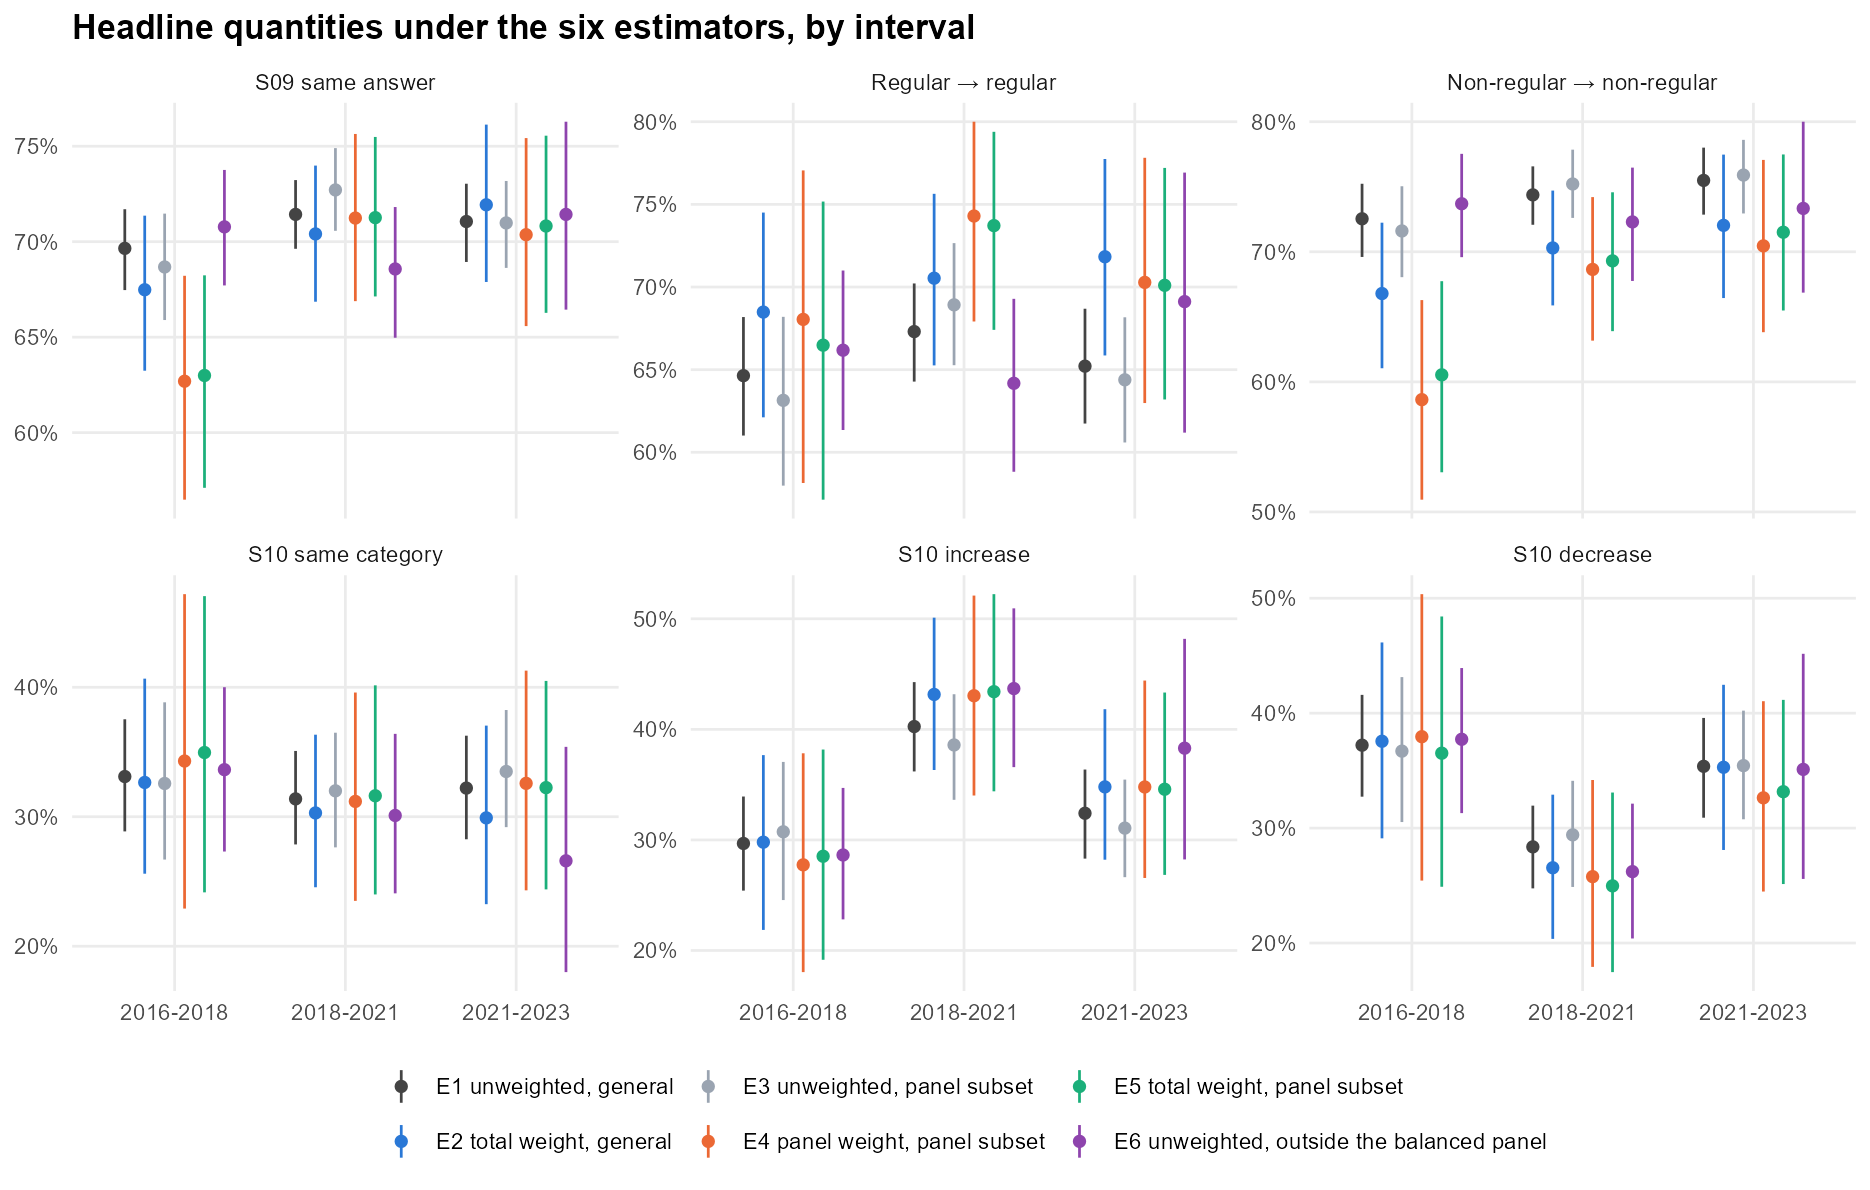

Elapsed: 0.02 minutes


In [5]:
#| label: elsoc-w-comparison
.t0 <- Sys.time()
cmp <- comparison[comparison$estimator %in% main_est, ]
for (period in periods) {
  z <- cmp[cmp$interval == period & cmp$group == "All" & cmp$quantity %in% key_q, ]; z <- z[order(match(z$quantity, key_q), match(z$estimator, main_est)), ]
  show_table(data.frame(Quantity = qty_label[z$quantity], Estimator = est_label[z$estimator], N = z$n, ESS = round(z$ess), Estimate = ci(z$estimate, z$lower, z$upper), Width = sprintf("%.1f pp", 100 * z$width), `SE bootstrap` = sprintf("%.3f", z$se_boot), `SE Taylor` = ifelse(is.na(z$se_taylor), "—", sprintf("%.3f", z$se_taylor)), check.names = FALSE),
    paste0(period, ": the six main estimators on all pairs. N is unweighted; percentages are weighted where the estimator has weights; 95% segment-bootstrap intervals"))
}
z <- cmp[cmp$group == "All" & cmp$quantity %in% key_q, ]
z$quantity <- factor(qty_label[z$quantity], levels = qty_label[key_q]); z$estimator <- factor(est_label[z$estimator], levels = est_label[main_est])
p <- ggplot2::ggplot(z, ggplot2::aes(x = interval, y = estimate, colour = estimator)) + ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(width = .7), size = .3) + ggplot2::facet_wrap(~quantity, scales = "free_y", ncol = 3) + ggplot2::scale_y_continuous(labels = scales::percent) + ggplot2::scale_colour_manual(values = est_colors) + ggplot2::labs(x = NULL, y = NULL, colour = NULL, title = "Headline quantities under the six estimators, by interval") + plot_theme() + ggplot2::guides(colour = ggplot2::guide_legend(nrow = 2))
show_plot(p, "comparison", 11, 7)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Weighting versus selection

The delta tables are the core of the notebook. Read each row as "estimator a minus estimator b, in percentage points, with its paired interval". A weighting effect that is large while the selection effects are small means the weights move the estimate for the same people; a selection effect that is large while weighting effects are small means the balanced panel is a different population. The figure drops the identity row.


Quantity,Contrast,N a,N b,a,b,Delta,95% CI
S09 same answer,"Weighting: E2 − E1 (same people, G)",1888,1888,67.5%,69.7%,-2.2 pp,[-5.9; +1.0]
S09 same answer,"Weighting: E4 − E3 (same people, P)",1012,1012,62.7%,68.7%,-6.0 pp,[-11.3; -1.1]
S09 same answer,"Weight variable: E4 − E5 (same people, P)",1012,1012,62.7%,63.0%,-0.3 pp,[-1.2; +0.5]
S09 same answer,"Selection, unweighted: E3 − E1",1012,1888,68.7%,69.7%,-1.0 pp,[-2.8; +0.8]
S09 same answer,"Selection, unweighted: E3 − E6 (balanced panel vs rest of G)",1012,876,68.7%,70.8%,-2.1 pp,[-6.2; +1.8]
S09 same answer,Selection under total weights: E5 − E2,1012,1888,63.0%,67.5%,-4.5 pp,[-8.1; -0.8]
S09 same answer,Scenario difference: E4 − E2 (identity),1012,1888,62.7%,67.5%,-4.8 pp,[-8.8; -0.9]
Regular → regular,"Weighting: E2 − E1 (same people, G)",690,690,68.5%,64.6%,+3.8 pp,[-1.7; +8.7]
Regular → regular,"Weighting: E4 − E3 (same people, P)",350,350,68.0%,63.1%,+4.9 pp,[-3.4; +12.8]
Regular → regular,"Weight variable: E4 − E5 (same people, P)",350,350,68.0%,66.5%,+1.6 pp,[+0.1; +2.8]


Quantity,Contrast,N a,N b,a,b,Delta,95% CI
S09 same answer,"Weighting: E2 − E1 (same people, G)",2261,2261,70.4%,71.4%,-1.0 pp,[-4.0; +1.9]
S09 same answer,"Weighting: E4 − E3 (same people, P)",1561,1561,71.2%,72.7%,-1.5 pp,[-5.3; +2.0]
S09 same answer,"Weight variable: E4 − E5 (same people, P)",1561,1561,71.2%,71.3%,-0.0 pp,[-0.5; +0.4]
S09 same answer,"Selection, unweighted: E3 − E1",1561,2261,72.7%,71.4%,+1.3 pp,[+0.1; +2.6]
S09 same answer,"Selection, unweighted: E3 − E6 (balanced panel vs rest of G)",1561,700,72.7%,68.6%,+4.1 pp,[+0.2; +8.3]
S09 same answer,Selection under total weights: E5 − E2,1561,2261,71.3%,70.4%,+0.9 pp,[-1.4; +3.2]
S09 same answer,Scenario difference: E4 − E2 (identity),1561,2261,71.2%,70.4%,+0.8 pp,[-1.6; +3.3]
Regular → regular,"Weighting: E2 − E1 (same people, G)",942,942,70.5%,67.3%,+3.2 pp,[-1.1; +7.4]
Regular → regular,"Weighting: E4 − E3 (same people, P)",621,621,74.3%,68.9%,+5.4 pp,[-0.3; +10.5]
Regular → regular,"Weight variable: E4 − E5 (same people, P)",621,621,74.3%,73.7%,+0.6 pp,[-0.0; +1.2]


Quantity,Contrast,N a,N b,a,b,Delta,95% CI
S09 same answer,"Weighting: E2 − E1 (same people, G)",1807,1807,71.9%,71.1%,+0.9 pp,[-2.4; +4.5]
S09 same answer,"Weighting: E4 − E3 (same people, P)",1506,1506,70.4%,71.0%,-0.6 pp,[-4.8; +3.7]
S09 same answer,"Weight variable: E4 − E5 (same people, P)",1506,1506,70.4%,70.8%,-0.5 pp,[-1.2; +0.2]
S09 same answer,"Selection, unweighted: E3 − E1",1506,1807,71.0%,71.1%,-0.1 pp,[-1.0; +0.9]
S09 same answer,"Selection, unweighted: E3 − E6 (balanced panel vs rest of G)",1506,301,71.0%,71.4%,-0.4 pp,[-5.8; +5.2]
S09 same answer,Selection under total weights: E5 − E2,1506,1807,70.8%,71.9%,-1.1 pp,[-3.0; +0.7]
S09 same answer,Scenario difference: E4 − E2 (identity),1506,1807,70.4%,71.9%,-1.6 pp,[-3.7; +0.6]
Regular → regular,"Weighting: E2 − E1 (same people, G)",779,779,71.8%,65.2%,+6.6 pp,[+1.7; +11.4]
Regular → regular,"Weighting: E4 − E3 (same people, P)",643,643,70.3%,64.4%,+5.9 pp,[-0.4; +11.8]
Regular → regular,"Weight variable: E4 − E5 (same people, P)",643,643,70.3%,70.1%,+0.2 pp,[-0.7; +1.0]


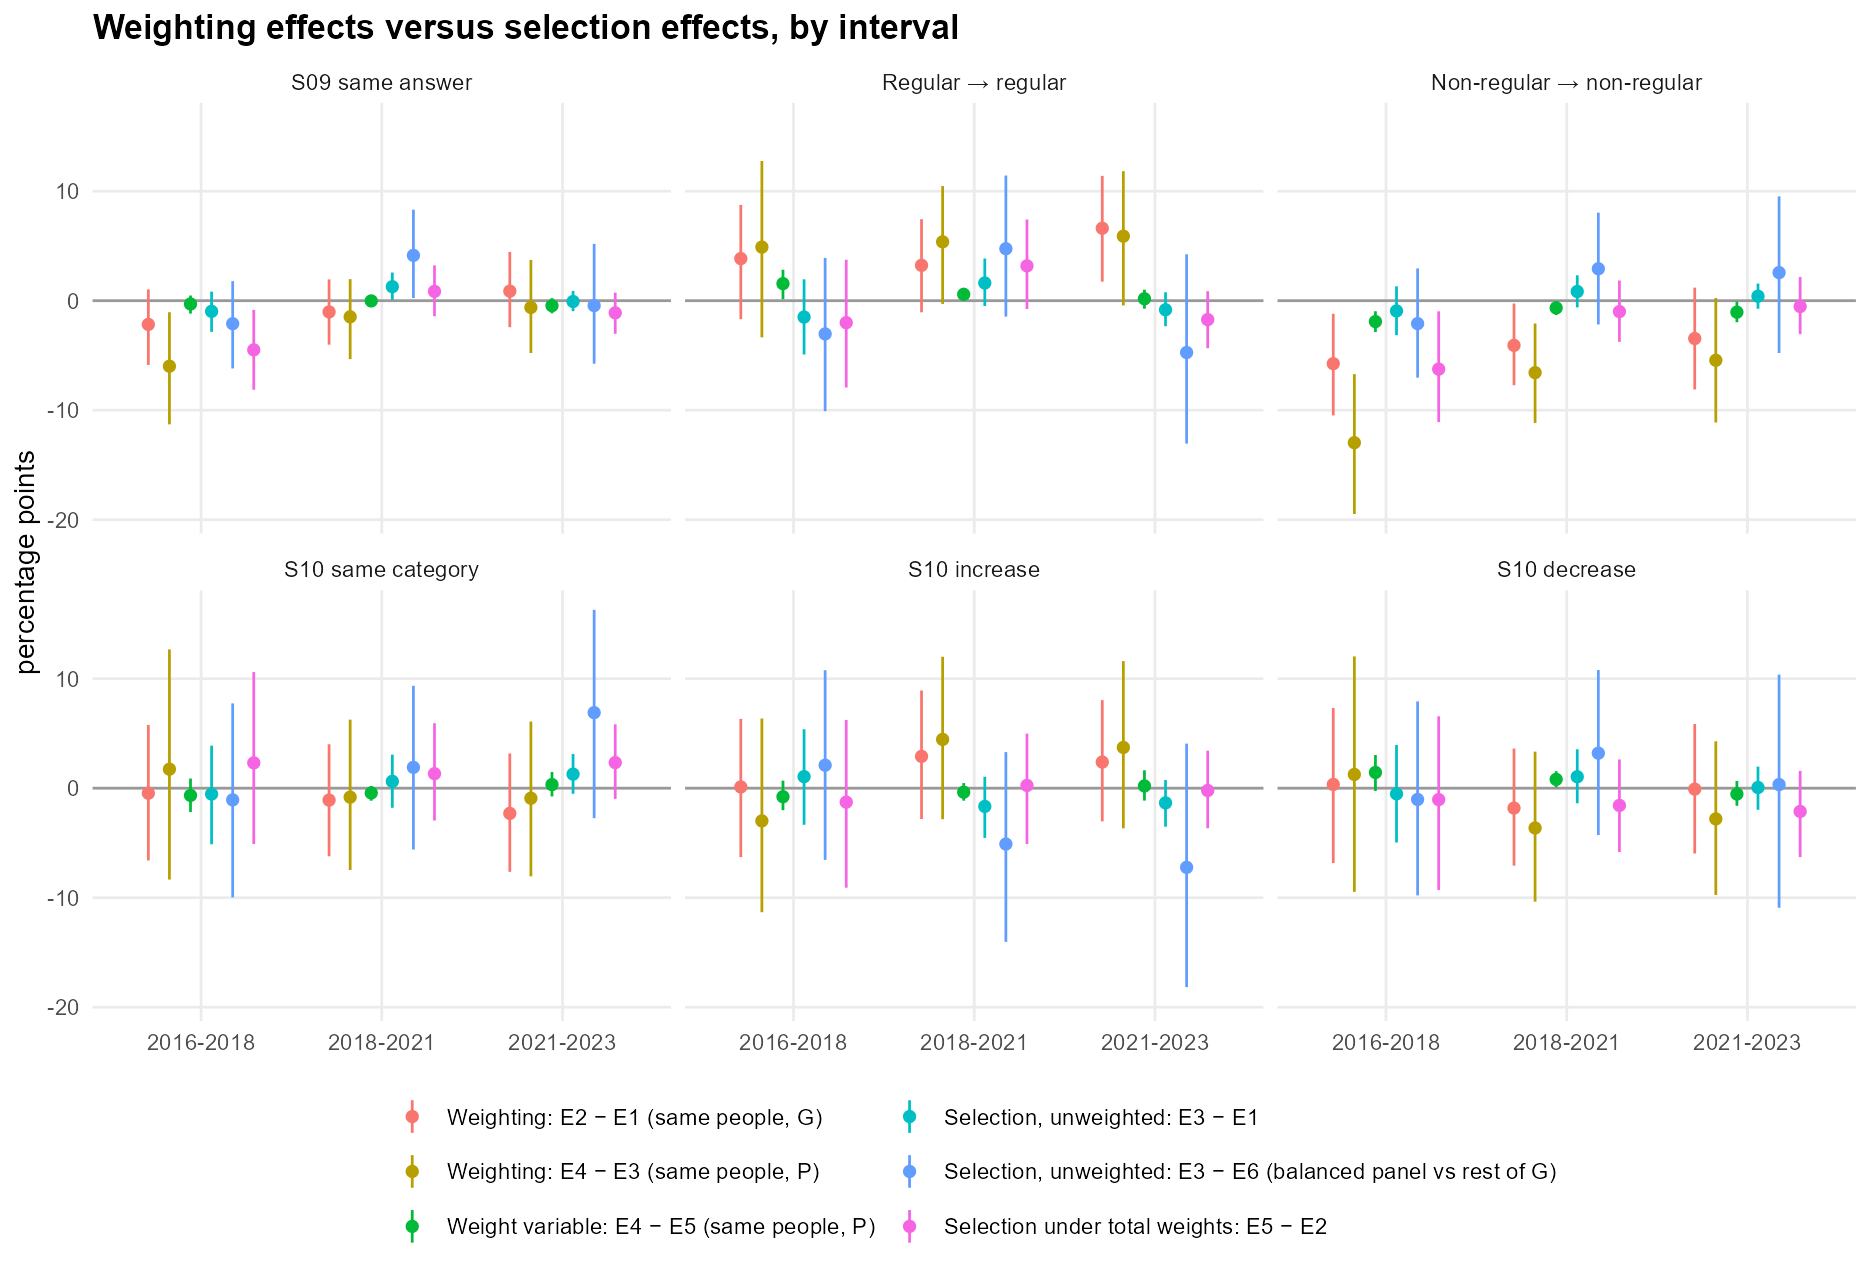

Elapsed: 0.01 minutes


In [6]:
#| label: elsoc-w-deltas
.t0 <- Sys.time()
for (period in periods) {
  z <- deltas[deltas$interval == period & deltas$group == "All" & deltas$quantity %in% key_q, ]; z <- z[order(match(z$quantity, key_q), match(z$contrast, names(contrast_label))), ]
  show_table(data.frame(Quantity = qty_label[z$quantity], Contrast = contrast_label[z$contrast], `N a` = z$n_a, `N b` = z$n_b, a = pct(z$estimate_a), b = pct(z$estimate_b), Delta = sprintf("%+.1f pp", 100 * z$delta), `95% CI` = ifelse(is.na(z$lower), "—", sprintf("[%+.1f; %+.1f]", 100 * z$lower, 100 * z$upper)), check.names = FALSE),
    paste0(period, ": paired differences a − b computed replicate by replicate on the common segment bootstrap, in percentage points"))
}
z <- deltas[deltas$group == "All" & deltas$quantity %in% key_q & deltas$contrast != "scenario_difference", ]
z$quantity <- factor(qty_label[z$quantity], levels = qty_label[key_q]); z$contrast <- factor(contrast_label[z$contrast], levels = contrast_label[names(contrast_label) != "scenario_difference"])
p <- ggplot2::ggplot(z, ggplot2::aes(x = interval, y = 100 * delta, colour = contrast)) + ggplot2::geom_hline(yintercept = 0, colour = "grey60") + ggplot2::geom_pointrange(ggplot2::aes(ymin = 100 * lower, ymax = 100 * upper), position = ggplot2::position_dodge(width = .7), size = .3) + ggplot2::facet_wrap(~quantity, ncol = 3) + ggplot2::labs(x = NULL, y = "percentage points", colour = NULL, title = "Weighting effects versus selection effects, by interval") + plot_theme() + ggplot2::guides(colour = ggplot2::guide_legend(nrow = 3))
show_plot(p, "deltas", 11, 7.5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Permanence in non-regular and in regular by sex and initial age

Permanence in "non-regular" is the probability of declaring non-regular at destination among those who declared non-regular at origin; its complement is the move to regular. It is shown with its origin N under the first four estimators, by interval and by sex × initial age band (18–29, 30–44, 45–59, 60–65). The last interval has no respondents aged 18–19 at origin. Cells with an origin N or an ESS below 30 are marked and should be read as indicative only. The figure compares the unweighted, total-weighted and panel-weighted versions.


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",71,71,57.7% [46.3%; 68.7%]
Men 18-29,"E2 total weight, general",71,28,55.9% [36.9%; 73.2%] *
Men 18-29,"E3 unweighted, panel subset",26,26,46.2% [26.1%; 65.0%] *
Men 18-29,"E4 panel weight, panel subset",26,8,29.9% [11.0%; 67.6%] *
Men 30-44,"E1 unweighted, general",92,92,58.7% [47.7%; 68.7%]
Men 30-44,"E2 total weight, general",92,28,52.2% [32.0%; 70.3%] *
Men 30-44,"E3 unweighted, panel subset",43,43,58.1% [42.3%; 72.2%]
Men 30-44,"E4 panel weight, panel subset",43,13,52.7% [24.7%; 79.7%] *
Men 45-59,"E1 unweighted, general",133,133,56.4% [47.7%; 64.7%]
Men 45-59,"E2 total weight, general",133,44,63.7% [49.5%; 77.5%]


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",75,75,85.3% [75.9%; 93.4%]
Men 18-29,"E2 total weight, general",75,28,84.6% [68.5%; 97.8%] *
Men 18-29,"E3 unweighted, panel subset",30,30,86.7% [73.7%; 96.9%]
Men 18-29,"E4 panel weight, panel subset",30,11,75.2% [46.7%; 99.9%] *
Men 30-44,"E1 unweighted, general",134,134,75.4% [68.3%; 82.1%]
Men 30-44,"E2 total weight, general",134,51,80.6% [69.3%; 89.6%]
Men 30-44,"E3 unweighted, panel subset",51,51,68.6% [55.3%; 80.9%]
Men 30-44,"E4 panel weight, panel subset",51,21,81.2% [64.6%; 92.5%] *
Men 45-59,"E1 unweighted, general",132,132,62.9% [54.3%; 71.2%]
Men 45-59,"E2 total weight, general",132,35,58.4% [43.1%; 73.5%]


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",60,60,58.3% [45.8%; 71.2%]
Men 18-29,"E2 total weight, general",60,20,59.1% [36.5%; 81.2%] *
Men 18-29,"E3 unweighted, panel subset",38,38,57.9% [41.3%; 73.0%]
Men 18-29,"E4 panel weight, panel subset",38,14,63.7% [37.0%; 87.0%] *
Men 30-44,"E1 unweighted, general",96,96,53.1% [42.9%; 62.9%]
Men 30-44,"E2 total weight, general",96,36,62.3% [47.0%; 76.4%]
Men 30-44,"E3 unweighted, panel subset",57,57,52.6% [40.0%; 64.9%]
Men 30-44,"E4 panel weight, panel subset",57,22,54.6% [32.0%; 74.4%] *
Men 45-59,"E1 unweighted, general",140,140,63.6% [55.4%; 72.0%]
Men 45-59,"E2 total weight, general",140,47,59.9% [44.8%; 74.3%]


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",99,99,70.7% [61.5%; 79.2%]
Men 18-29,"E2 total weight, general",99,34,65.8% [49.0%; 80.8%]
Men 18-29,"E3 unweighted, panel subset",57,57,71.9% [60.5%; 83.3%]
Men 18-29,"E4 panel weight, panel subset",57,20,72.3% [51.8%; 89.0%] *
Men 30-44,"E1 unweighted, general",168,168,76.2% [69.9%; 82.5%]
Men 30-44,"E2 total weight, general",168,69,83.0% [74.0%; 90.7%]
Men 30-44,"E3 unweighted, panel subset",93,93,76.3% [67.9%; 84.8%]
Men 30-44,"E4 panel weight, panel subset",93,35,83.8% [71.1%; 93.8%]
Men 45-59,"E1 unweighted, general",154,154,72.7% [65.3%; 79.5%]
Men 45-59,"E2 total weight, general",154,47,72.3% [59.5%; 84.1%]


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",45,45,55.6% [40.0%; 70.7%]
Men 18-29,"E2 total weight, general",45,17,64.9% [39.3%; 84.3%] *
Men 18-29,"E3 unweighted, panel subset",33,33,51.5% [34.5%; 69.5%]
Men 18-29,"E4 panel weight, panel subset",33,12,60.3% [29.5%; 84.1%] *
Men 30-44,"E1 unweighted, general",67,67,67.2% [55.3%; 78.0%]
Men 30-44,"E2 total weight, general",67,23,72.5% [52.0%; 89.6%] *
Men 30-44,"E3 unweighted, panel subset",51,51,66.7% [53.3%; 79.6%]
Men 30-44,"E4 panel weight, panel subset",51,17,64.4% [40.6%; 86.6%] *
Men 45-59,"E1 unweighted, general",95,95,62.1% [52.6%; 72.0%]
Men 45-59,"E2 total weight, general",95,27,60.6% [42.4%; 77.5%] *


Group,Estimator,N,ESS,Estimate
Men 18-29,"E1 unweighted, general",50,50,78.0% [66.7%; 89.1%]
Men 18-29,"E2 total weight, general",50,18,91.6% [77.9%; 99.1%] *
Men 18-29,"E3 unweighted, panel subset",39,39,79.5% [65.8%; 91.9%]
Men 18-29,"E4 panel weight, panel subset",39,14,92.1% [76.9%; 99.8%] *
Men 30-44,"E1 unweighted, general",136,136,72.1% [64.8%; 79.0%]
Men 30-44,"E2 total weight, general",136,59,70.9% [58.4%; 83.1%]
Men 30-44,"E3 unweighted, panel subset",101,101,69.3% [60.6%; 78.0%]
Men 30-44,"E4 panel weight, panel subset",101,39,62.6% [46.6%; 79.1%]
Men 45-59,"E1 unweighted, general",133,133,74.4% [66.9%; 82.0%]
Men 45-59,"E2 total weight, general",133,45,80.8% [69.0%; 91.1%]


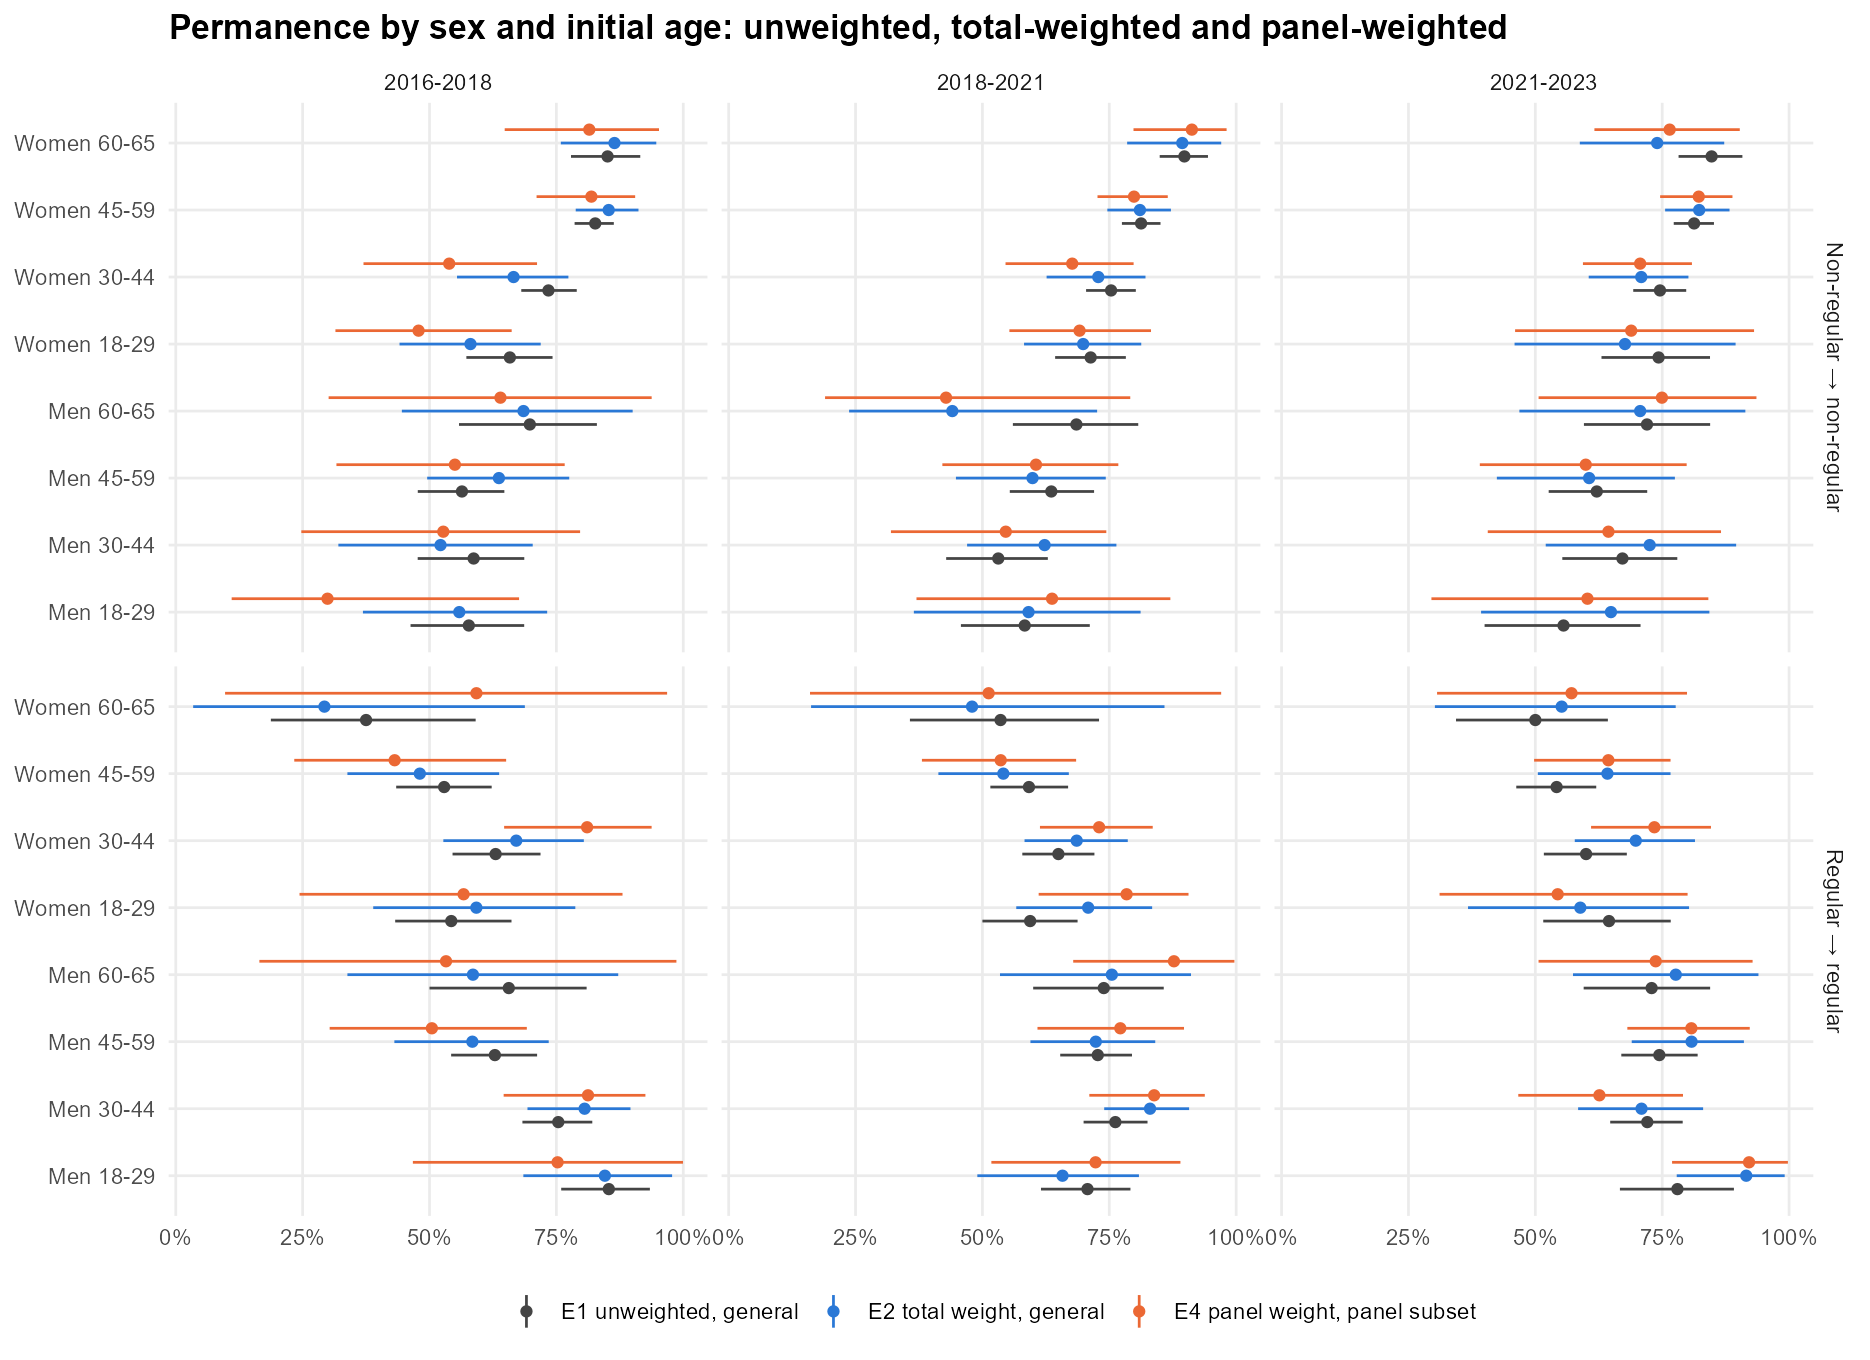

Elapsed: 0.01 minutes


In [7]:
#| label: elsoc-w-groups
.t0 <- Sys.time()
sa <- comparison[comparison$estimator %in% main_est[1:4] & grepl("^(Men|Women)_", comparison$group) & comparison$quantity %in% c("regular_stay", "nonregular_stay"), ]
for (period in periods) for (q in c("nonregular_stay", "regular_stay")) { z <- sa[sa$interval == period & sa$quantity == q, ]; z <- z[order(z$group, match(z$estimator, main_est)), ]
  show_table(data.frame(Group = group_label(z$group), Estimator = est_label[z$estimator], N = z$n, ESS = round(z$ess), Estimate = ci(z$estimate, z$lower, z$upper, z$n < 30 | z$ess < 30)), paste0(period, ": ", qty_label[q], " by sex and initial age; * origin N or ESS below 30")) }
z <- sa[sa$estimator %in% c("unweighted_general", "total_general", "panel_panel_subset"), ]
z$estimator <- factor(est_label[z$estimator], levels = est_label[c("unweighted_general", "total_general", "panel_panel_subset")]); z$quantity <- qty_label[z$quantity]; z$group <- group_label(z$group)
p <- ggplot2::ggplot(z, ggplot2::aes(x = group, y = estimate, colour = estimator)) + ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(width = .6), size = .25) + ggplot2::facet_grid(quantity ~ interval) + ggplot2::coord_flip() + ggplot2::scale_y_continuous(labels = scales::percent) + ggplot2::scale_colour_manual(values = est_colors[c(1, 2, 4)]) + ggplot2::labs(x = NULL, y = NULL, colour = NULL, title = "Permanence by sex and initial age: unweighted, total-weighted and panel-weighted") + plot_theme()
show_plot(p, "groups", 11, 8)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Frequency among regular drinkers

S10 transitions exist only for people regular at both ends with a valid frequency, so they describe neither all drinkers nor the whole panel, and the selection into this subset changes between periods. The tables show the direction of change (same category, increase, decrease) under the six estimators. The weighted 8×8 matrices are written to the CSV but not displayed: once the weights spread a few hundred pairs over eight origin categories, most cells fall below the effective-sample-size threshold, and the categories are not collapsed because the user asked to keep the original ones.


In [8]:
#| label: elsoc-w-s10
.t0 <- Sys.time()
z <- comparison[comparison$estimator %in% main_est & comparison$group %in% c("All", "M1", "M2") & comparison$quantity %in% c("s10_same", "s10_increase", "s10_decrease"), ]
for (period in periods) { y <- z[z$interval == period, ]; y <- y[order(y$group, match(y$quantity, key_q), match(y$estimator, main_est)), ]
  show_table(data.frame(Group = y$group, Quantity = qty_label[y$quantity], Estimator = est_label[y$estimator], N = y$n, ESS = round(y$ess), Estimate = ci(y$estimate, y$lower, y$upper, y$ess < 30)), paste0(period, ": direction of change in S10 among regular drinkers with a valid frequency at both ends; * ESS below 30")) }
m <- matrices[matrices$item == "s10" & matrices$estimator %in% c("total_general", "panel_panel_subset") & matrices$group == "All" & matrices$n_origin > 0, ]
fl <- stats::aggregate(cbind(flagged = m$small_ess | m$small_origin | m$rare_event, cells = 1), by = list(interval = m$interval, estimator = est_label[m$estimator]), FUN = sum)
show_table(fl, "Weighted S10 8×8 matrices for all pairs: cells with a non-empty origin flagged for small origin, rare event or ESS below 30; the matrices stay in weights_transition_matrices.csv")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Group,Quantity,Estimator,N,ESS,Estimate
All,S10 same category,"E1 unweighted, general",438,438,33.1% [28.9%; 37.5%]
All,S10 same category,"E2 total weight, general",438,144,32.6% [25.6%; 40.7%]
All,S10 same category,"E3 unweighted, panel subset",218,218,32.6% [26.7%; 38.8%]
All,S10 same category,"E4 panel weight, panel subset",218,57,34.3% [22.9%; 47.2%]
All,S10 same category,"E5 total weight, panel subset",218,63,35.0% [24.2%; 47.0%]
All,S10 same category,"E6 unweighted, outside the balanced panel",220,220,33.6% [27.3%; 40.0%]
All,S10 increase,"E1 unweighted, general",438,438,29.7% [25.4%; 33.9%]
All,S10 increase,"E2 total weight, general",438,144,29.8% [21.9%; 37.7%]
All,S10 increase,"E3 unweighted, panel subset",218,218,30.7% [24.6%; 37.1%]
All,S10 increase,"E4 panel weight, panel subset",218,57,27.7% [18.0%; 37.8%]


Group,Quantity,Estimator,N,ESS,Estimate
All,S10 same category,"E1 unweighted, general",631,631,31.4% [27.9%; 35.1%]
All,S10 same category,"E2 total weight, general",631,196,30.3% [24.6%; 36.3%]
All,S10 same category,"E3 unweighted, panel subset",425,425,32.0% [27.6%; 36.5%]
All,S10 same category,"E4 panel weight, panel subset",425,116,31.2% [23.5%; 39.6%]
All,S10 same category,"E5 total weight, panel subset",425,121,31.6% [24.0%; 40.1%]
All,S10 same category,"E6 unweighted, outside the balanced panel",206,206,30.1% [24.1%; 36.4%]
All,S10 increase,"E1 unweighted, general",631,631,40.3% [36.2%; 44.3%]
All,S10 increase,"E2 total weight, general",631,196,43.2% [36.3%; 50.1%]
All,S10 increase,"E3 unweighted, panel subset",425,425,38.6% [33.6%; 43.2%]
All,S10 increase,"E4 panel weight, panel subset",425,116,43.0% [34.0%; 52.1%]


Group,Quantity,Estimator,N,ESS,Estimate
All,S10 same category,"E1 unweighted, general",506,506,32.2% [28.3%; 36.3%]
All,S10 same category,"E2 total weight, general",506,176,29.9% [23.2%; 37.0%]
All,S10 same category,"E3 unweighted, panel subset",412,412,33.5% [29.2%; 38.2%]
All,S10 same category,"E4 panel weight, panel subset",412,119,32.6% [24.3%; 41.3%]
All,S10 same category,"E5 total weight, panel subset",412,135,32.2% [24.4%; 40.5%]
All,S10 same category,"E6 unweighted, outside the balanced panel",94,94,26.6% [18.0%; 35.4%]
All,S10 increase,"E1 unweighted, general",506,506,32.4% [28.3%; 36.4%]
All,S10 increase,"E2 total weight, general",506,176,34.8% [28.2%; 41.8%]
All,S10 increase,"E3 unweighted, panel subset",412,412,31.1% [26.6%; 35.5%]
All,S10 increase,"E4 panel weight, panel subset",412,119,34.8% [26.6%; 44.4%]


interval,estimator,flagged,cells
2016-2018,"E2 total weight, general",53,64
2018-2021,"E2 total weight, general",45,64
2021-2023,"E2 total weight, general",50,64
2016-2018,"E4 panel weight, panel subset",64,64
2018-2021,"E4 panel weight, panel subset",52,64
2021-2023,"E4 panel weight, panel subset",59,64


Elapsed: 0.00 minutes


## Composition: the official check and the balance diagnostic

The official report recommends, for an analysis that combines waves, to compare the sex × age composition of the filtered set with the composition of all respondents and of the balanced panel, and to use the weight whose population it resembles. The first table implements that check with the five INE age bands at the origin wave, among people aged 18–65 at that wave, where the three sets share the same age window; at the destination wave the pairs reach age 72 while the reference domains would stop at 65, so that comparison is not made. The second table is the EPS-style balance diagnostic: the largest standardized mean difference, per contrast, over sex, initial age, sample, education and the S09 origin state. The figure shows what the weights and the panel selection do to the age composition of the pairs.


interval,wave,sample,n_pairs,n_wave_18_65,n_balanced_panel_18_65,max_abs_smd_pairs_vs_wave,max_abs_smd_pairs_vs_panel,closer_to
2016-2018,w1,M1,1888,2562,1031,0.044,0.093,all respondents (total weight)
2018-2021,w3,M1,1367,1865,989,0.060,0.059,balanced panel (panel weight)
2018-2021,w3,M2,894,1356,586,0.052,0.082,all respondents (total weight)
2021-2023,w5,M1,1136,1422,944,0.047,0.032,balanced panel (panel weight)
2021-2023,w5,M2,671,878,567,0.033,0.046,all respondents (total weight)


interval,contrast,max_abs_smd,at,share_a,share_b,levels_above_0_1
2016-2018,"Weighting: E2 − E1 (same people, G)",0.329,age_group 18-29,0.318,0.178,6
2016-2018,"Weighting: E4 − E3 (same people, P)",0.369,age_group 18-29,0.311,0.157,7
2016-2018,"Weight variable: E4 − E5 (same people, P)",0.101,age_group 45-59,0.277,0.324,1
2016-2018,"Selection, unweighted: E3 − E1",0.124,sex Men,0.318,0.377,2
2016-2018,"Selection, unweighted: E3 − E6 (balanced panel vs rest of G)",0.264,sex Men,0.318,0.445,4
2016-2018,Selection under total weights: E5 − E2,0.107,age_group 45-59,0.324,0.275,1
2016-2018,Scenario difference: E4 − E2 (identity),0.063,education Unknown,0.000,0.002,0
2018-2021,"Weighting: E2 − E1 (same people, G)",0.325,age_group 18-29,0.316,0.178,6
2018-2021,"Weighting: E4 − E3 (same people, P)",0.365,age_group 18-29,0.315,0.162,9
2018-2021,"Weight variable: E4 − E5 (same people, P)",0.063,sex Women,0.518,0.550,0


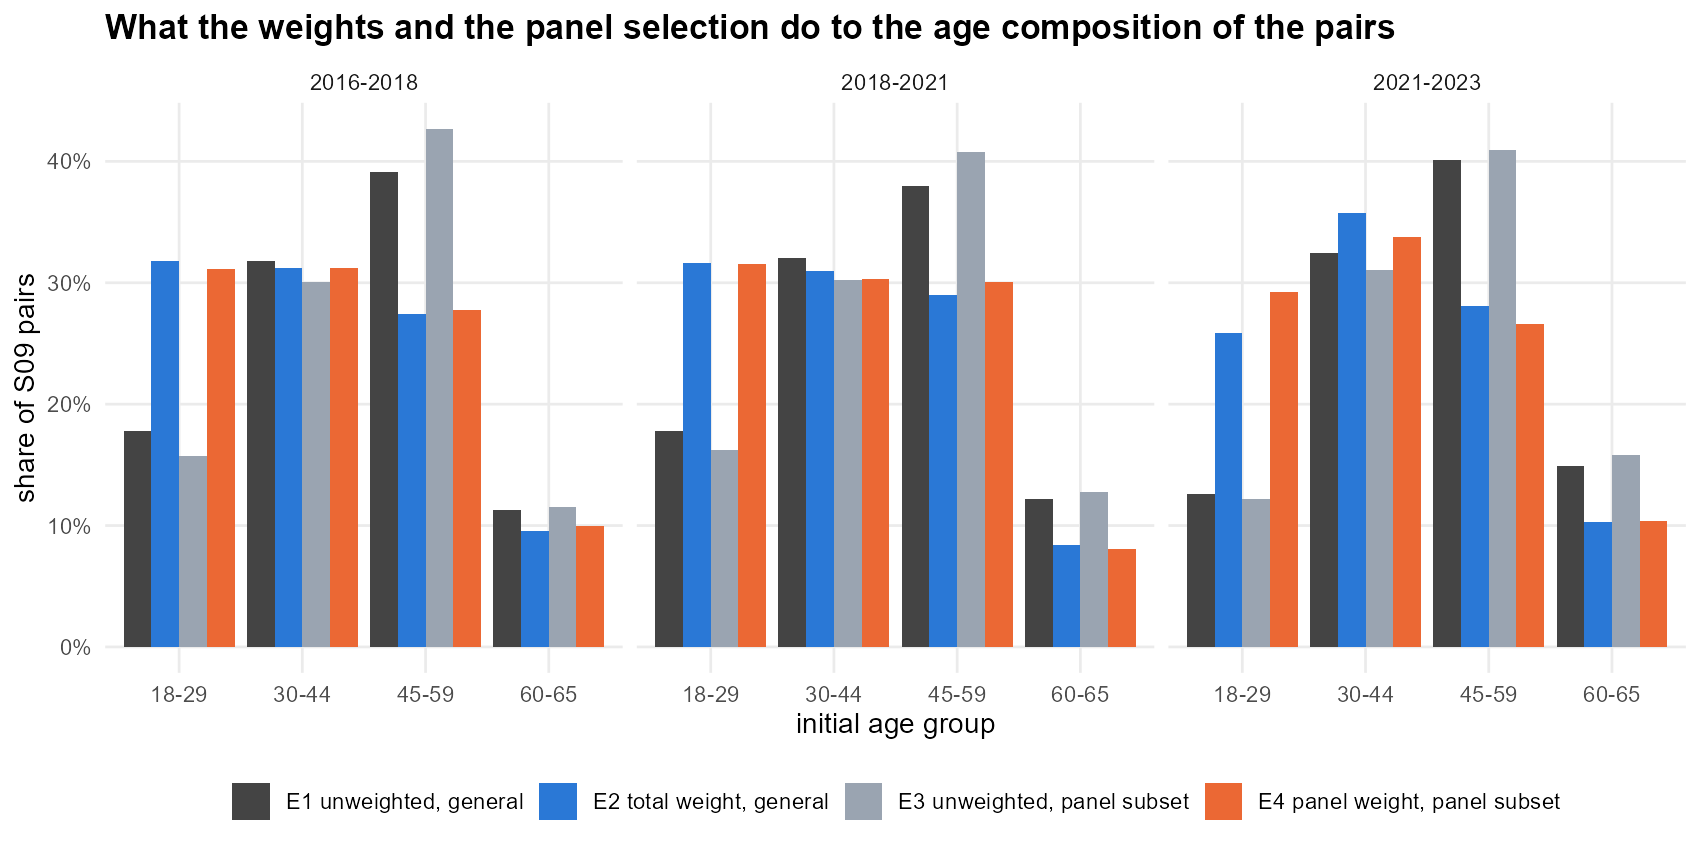

Elapsed: 0.01 minutes


In [9]:
#| label: elsoc-w-composition
.t0 <- Sys.time()
co <- wt("composition_official")
sm <- do.call(rbind, lapply(split(co, list(co$interval, co$wave, co$sample), drop = TRUE), function(z) data.frame(interval = z$interval[1], wave = sprintf("w%s", z$wave[1]), sample = z$sample[1], n_pairs = z$n_pairs[1], n_wave_18_65 = z$n_wave[1], n_balanced_panel_18_65 = z$n_panel[1],
  max_abs_smd_pairs_vs_wave = max(abs(z$smd_pairs_vs_wave)), max_abs_smd_pairs_vs_panel = max(abs(z$smd_pairs_vs_panel)), closer_to = ifelse(max(abs(z$smd_pairs_vs_wave)) <= max(abs(z$smd_pairs_vs_panel)), "all respondents (total weight)", "balanced panel (panel weight)"))))
show_table(sm[order(sm$interval, sm$wave, sm$sample), ], "Official composition check, unweighted sex × five INE age bands among people aged 18 to 65 at the origin wave: are the pairs closer to all respondents of that wave or to the balanced panel?", digits = 3)
smd <- wt("composition_smd"); smd$abs <- abs(smd$smd)
top <- do.call(rbind, lapply(split(smd, list(smd$interval, smd$contrast), drop = TRUE), function(z) { i <- which.max(z$abs); data.frame(interval = z$interval[1], contrast = contrast_label[z$contrast[1]], max_abs_smd = z$abs[i], at = paste(z$covariate[i], z$level[i]), share_a = z$share_a[i], share_b = z$share_b[i], levels_above_0_1 = sum(z$abs > .1)) }))
show_table(top[order(top$interval, match(top$contrast, contrast_label)), ], "EPS-style balance: largest standardized mean difference per contrast over sex, initial age, sample, education and S09 origin state", digits = 3)
bal <- wt("composition_balance"); b <- bal[bal$estimator %in% main_est[1:4] & bal$covariate == "age_group", ]
b$estimator <- factor(est_label[b$estimator], levels = est_label[main_est[1:4]])
p <- ggplot2::ggplot(b, ggplot2::aes(x = level, y = share, fill = estimator)) + ggplot2::geom_col(position = "dodge") + ggplot2::facet_wrap(~interval) + ggplot2::scale_y_continuous(labels = scales::percent) + ggplot2::scale_fill_manual(values = est_colors[1:4]) + ggplot2::labs(x = "initial age group", y = "share of S09 pairs", fill = NULL, title = "What the weights and the panel selection do to the age composition of the pairs") + plot_theme()
show_plot(p, "composition", 10, 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Precision: effective sample size, cross-check and sensitivities

The weights are dispersed by construction: the trimming of the official procedure is applied before calibration and over all waves pooled, so within a wave the tails are intact and the effective sample size is a fraction of N. The diagnostics table reports N, the sum of weights, the Kish ESS, the unequal weighting effect and the concentration in the top 1 %. The Taylor table compares the bootstrap and the linearized standard errors over the headline cells. Two sensitivities follow: capping the weights at the 99th percentile of their wave × sample without re-raking, with the shift this induces in the weighted sex × age shares, and using the origin-wave weight instead of the destination-wave weight. The by-stratum table shows where the dispersion comes from.


In [10]:
#| label: elsoc-w-precision
.t0 <- Sys.time()
dg <- wt("diagnostics"); dg <- dg[dg$item == "s09", c("interval", "estimator", "n", "sum_w", "ess", "unequal_weighting_effect", "max_over_mean", "top1_share")]; dg$estimator <- est_label[dg$estimator]
show_table(dg, "Weight diagnostics on S09 pairs: Kish effective sample size, unequal weighting effect n/ESS and concentration of the weights", digits = 2)
tc <- wt("taylor_check"); tc <- tc[tc$estimator %in% main_est, ]
ts <- do.call(rbind, lapply(split(tc, list(tc$interval, tc$estimator), drop = TRUE), function(z) data.frame(interval = z$interval[1], estimator = est_label[z$estimator[1]], cells = nrow(z), median_ratio = stats::median(z$se_ratio, na.rm = TRUE), p10 = stats::quantile(z$se_ratio, .1, na.rm = TRUE), p90 = stats::quantile(z$se_ratio, .9, na.rm = TRUE), flagged = sum(z$se_ratio_flag), flagged_max_origin_n = if (any(z$se_ratio_flag)) max(z$n_origin[z$se_ratio_flag]) else NA)))
show_table(ts[order(ts$interval, match(ts$estimator, est_label)), ], "Bootstrap SE divided by Taylor SE with the same clustering (segments within strata) over the headline cells; flagged outside 0.8–1.25", digits = 3)
cb <- comparison[comparison$group == "All" & comparison$quantity %in% key_q, ]
tr <- merge(cb[cb$estimator %in% c("total_general", "panel_panel_subset", "total_panel_subset"), c("interval", "quantity", "estimator", "estimate", "width")], cb[cb$estimator %in% c("total_general_trimmed", "panel_panel_subset_trimmed", "total_panel_subset_trimmed"), c("interval", "quantity", "estimator", "estimate", "width")], by = c("interval", "quantity"), suffixes = c("", "_trimmed"))
tr <- tr[sub("_trimmed$", "", tr$estimator_trimmed) == tr$estimator, ]; tr <- tr[order(tr$interval, match(tr$quantity, key_q), tr$estimator), ]
show_table(data.frame(interval = tr$interval, quantity = qty_label[tr$quantity], estimator = est_label[tr$estimator], untrimmed = pct(tr$estimate), trimmed_p99 = pct(tr$estimate_trimmed), shift_pp = sprintf("%+.2f", 100 * (tr$estimate_trimmed - tr$estimate)), width_untrimmed_pp = sprintf("%.1f", 100 * tr$width), width_trimmed_pp = sprintf("%.1f", 100 * tr$width_trimmed)), "Trimming sensitivity: destination weights capped at the 99th percentile of their wave × sample, no re-raking")
show_table(wt("trimming"), "Caps, pairs affected, ESS gain and the shift induced in the weighted sex × age-band shares of the pairs", digits = 3)
ow <- merge(cb[cb$estimator %in% c("total_general", "panel_panel_subset"), c("interval", "quantity", "estimator", "estimate")], cb[cb$estimator %in% c("total_general_origin_wave", "panel_panel_subset_origin_wave"), c("interval", "quantity", "estimator", "estimate")], by = c("interval", "quantity"), suffixes = c("", "_origin"))
ow <- ow[sub("_origin_wave$", "", ow$estimator_origin) == ow$estimator, ]; ow <- ow[order(ow$interval, match(ow$quantity, key_q), ow$estimator), ]
show_table(data.frame(interval = ow$interval, quantity = qty_label[ow$quantity], estimator = est_label[ow$estimator], destination_wave_weight = pct(ow$estimate), origin_wave_weight = pct(ow$estimate_origin), shift_pp = sprintf("%+.2f", 100 * (ow$estimate_origin - ow$estimate))), "Sensitivity to the wave of the weight: destination-wave weight (main) versus origin-wave weight")
show_table(wt("by_stratum"), "Destination weight by design stratum on the S09 pairs: where the dispersion of the weights comes from", digits = 3)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


interval,estimator,n,sum_w,ess,unequal_weighting_effect,max_over_mean,top1_share
2016-2018,"E1 unweighted, general",1888,1888.00,1888.00,1.00,1.00,0.01
2016-2018,"E2 total weight, general",1888,1971.28,570.52,3.31,8.57,0.08
2016-2018,"E3 unweighted, panel subset",1012,1012.00,1012.00,1.00,1.00,0.01
2016-2018,"E4 panel weight, panel subset",1012,1059.83,250.56,4.04,11.62,0.10
2016-2018,"E5 total weight, panel subset",1012,959.12,284.97,3.55,9.44,0.08
2016-2018,"E6 unweighted, outside the balanced panel",876,876.00,876.00,1.00,1.00,0.01
2016-2018,E2 trimmed at p99,1888,1927.51,602.76,3.13,5.97,0.06
2016-2018,E4 trimmed at p99,1012,1032.10,270.01,3.75,7.66,0.08
2016-2018,E5 trimmed at p99,1012,941.97,298.18,3.39,6.55,0.06
2016-2018,E2 with origin-wave weight,1888,1781.19,623.01,3.03,7.03,0.06


interval,estimator,cells,median_ratio,p10,p90,flagged,flagged_max_origin_n
2016-2018,"E1 unweighted, general",80,1.002,0.973,1.020,3,9
2016-2018,"E2 total weight, general",80,1.004,0.980,1.031,3,9
2016-2018,"E3 unweighted, panel subset",80,1.004,0.973,1.025,3,8
2016-2018,"E4 panel weight, panel subset",80,1.013,0.979,1.060,7,24
2016-2018,"E5 total weight, panel subset",80,1.013,0.980,1.058,7,24
2016-2018,"E6 unweighted, outside the balanced panel",77,1.006,0.985,1.037,1,8
2018-2021,"E1 unweighted, general",88,1.002,0.982,1.032,0,NA
2018-2021,"E2 total weight, general",88,1.005,0.988,1.029,3,15
2018-2021,"E3 unweighted, panel subset",88,1.000,0.981,1.027,0,NA
2018-2021,"E4 panel weight, panel subset",88,1.002,0.979,1.054,3,14


interval,quantity,estimator,untrimmed,trimmed_p99,shift_pp,width_untrimmed_pp,width_trimmed_pp
2016-2018,S09 same answer,"E4 panel weight, panel subset",62.7%,62.9%,+0.21,11.7,11.1
2016-2018,S09 same answer,"E2 total weight, general",67.5%,67.5%,-0.02,8.1,7.8
2016-2018,S09 same answer,"E5 total weight, panel subset",63.0%,63.1%,+0.15,11.1,10.9
2016-2018,Regular → regular,"E4 panel weight, panel subset",68.0%,68.0%,-0.01,18.9,18.0
2016-2018,Regular → regular,"E2 total weight, general",68.5%,68.3%,-0.15,12.4,12.3
2016-2018,Regular → regular,"E5 total weight, panel subset",66.5%,66.4%,-0.04,18.0,17.7
2016-2018,Non-regular → non-regular,"E4 panel weight, panel subset",58.6%,59.2%,+0.53,15.3,15.2
2016-2018,Non-regular → non-regular,"E2 total weight, general",66.8%,66.9%,+0.07,11.2,11.0
2016-2018,Non-regular → non-regular,"E5 total weight, panel subset",60.5%,60.9%,+0.35,14.7,14.6
2016-2018,S10 same category,"E4 panel weight, panel subset",34.3%,33.7%,-0.61,24.3,22.9


interval,weight_family,sample,cap_p99,n_pairs,n_capped,ess_untrimmed,ess_trimmed,max_abs_shift_sex_tramo_share,mean_abs_shift_sex_tramo_share
2016-2018,total,M1,6.099,1888,22,570.523,602.758,0.018,0.004
2016-2018,panel,M1,7.811,1012,10,250.564,270.012,0.023,0.005
2018-2021,total,M1,7.274,1367,16,371.338,417.289,0.023,0.005
2018-2021,total,M2,6.225,894,7,295.933,303.534,0.004,0.001
2018-2021,panel,M1,7.882,983,12,234.666,270.000,0.032,0.006
2018-2021,panel,M2,6.363,578,7,188.081,198.686,0.012,0.003
2021-2023,total,M1,7.973,1136,11,300.242,341.262,0.018,0.005
2021-2023,total,M2,6.634,671,7,216.670,220.882,0.005,0.001
2021-2023,panel,M1,8.886,940,11,201.505,241.310,0.026,0.006
2021-2023,panel,M2,7.187,566,7,170.828,179.718,0.013,0.003


interval,quantity,estimator,destination_wave_weight,origin_wave_weight,shift_pp
2016-2018,S09 same answer,"E4 panel weight, panel subset",62.7%,63.2%,+0.47
2016-2018,S09 same answer,"E2 total weight, general",67.5%,67.7%,+0.19
2016-2018,Regular → regular,"E4 panel weight, panel subset",68.0%,68.3%,+0.22
2016-2018,Regular → regular,"E2 total weight, general",68.5%,67.3%,-1.20
2016-2018,Non-regular → non-regular,"E4 panel weight, panel subset",58.6%,59.4%,+0.74
2016-2018,Non-regular → non-regular,"E2 total weight, general",66.8%,67.9%,+1.14
2016-2018,S10 same category,"E4 panel weight, panel subset",34.3%,34.2%,-0.13
2016-2018,S10 same category,"E2 total weight, general",32.6%,34.4%,+1.77
2016-2018,S10 increase,"E4 panel weight, panel subset",27.7%,26.1%,-1.63
2016-2018,S10 increase,"E2 total weight, general",29.8%,30.9%,+1.07


interval,weight_family,sample,stratum,n,median_w,p05,p95,max_w
2016-2018,total,M1,1,438,2.798,0.982,6.161,8.951
2016-2018,total,M1,2,240,0.788,0.276,2.273,5.679
2016-2018,total,M1,3,256,0.597,0.244,2.032,4.178
2016-2018,total,M1,4,287,0.180,0.066,0.698,1.068
2016-2018,total,M1,5,355,0.030,0.009,0.111,0.202
2016-2018,total,M1,6,312,0.011,0.004,0.033,0.167
2016-2018,panel,M1,1,223,2.611,0.916,7.811,12.172
2016-2018,panel,M1,2,124,0.792,0.312,2.197,7.723
2016-2018,panel,M1,3,132,0.597,0.235,2.099,4.545
2016-2018,panel,M1,4,157,0.174,0.057,0.941,1.452


Elapsed: 0.00 minutes


## Education as an additional margin

Education at origin is recoded into three completed levels (basic or less, secondary, higher) from the ELSOC item, which asks for the current level when studying and the last approved level otherwise; it is an approximation that loses years, track and student status and does not certify a degree. It is offered as a margin, unweighted and total-weighted, not as a model with interactions.


In [11]:
#| label: elsoc-w-education
.t0 <- Sys.time()
ed <- changes[changes$estimator %in% c("unweighted_general", "total_general") & grepl("^Education_", changes$group) & changes$item == "s09" & changes$event == "same", ]
nr <- matrices[matrices$estimator %in% c("unweighted_general", "total_general") & grepl("^Education_", matrices$group) & matrices$item == "s09" & matrices$from == 2 & matrices$to == 2, ]
tab <- merge(data.frame(interval = ed$interval, education = group_label(ed$group), estimator = est_label[ed$estimator], N = ed$n_origin, `S09 same answer` = ci(ed$estimate, ed$lower, ed$upper, ed$small_origin), check.names = FALSE),
  data.frame(interval = nr$interval, education = group_label(nr$group), estimator = est_label[nr$estimator], `N non-regular at origin` = nr$n_origin, `Non-regular → non-regular` = ci(nr$estimate, nr$lower, nr$upper, nr$small_origin), check.names = FALSE), by = c("interval", "education", "estimator"))
show_table(tab[order(tab$interval, tab$education, tab$estimator), ], "Education completed at origin (approximate three-level recode of m01) as an additional margin, unweighted and total-weighted; * origin N below 30")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


interval,education,estimator,N,S09 same answer,N non-regular at origin,Non-regular → non-regular
2016-2018,Basic or less,"E1 unweighted, general",622,71.5% [68.2%; 75.0%],418,75.4% [71.2%; 79.4%]
2016-2018,Basic or less,"E2 total weight, general",622,67.0% [59.3%; 74.1%],418,69.8% [61.3%; 78.4%]
2016-2018,Higher,"E1 unweighted, general",482,65.1% [60.8%; 69.3%],271,66.8% [61.0%; 72.5%]
2016-2018,Higher,"E2 total weight, general",482,62.3% [54.8%; 69.3%],271,60.4% [49.8%; 70.9%]
2016-2018,Secondary,"E1 unweighted, general",783,70.9% [67.7%; 74.0%],508,73.2% [69.0%; 77.1%]
2016-2018,Secondary,"E2 total weight, general",783,71.3% [65.3%; 77.1%],508,68.8% [60.1%; 76.4%]
2016-2018,Unknown,"E1 unweighted, general",1,100.0% [no CI] *,1,100.0% [no CI] *
2016-2018,Unknown,"E2 total weight, general",1,100.0% [no CI] *,1,100.0% [no CI] *
2018-2021,Basic or less,"E1 unweighted, general",631,73.2% [70.0%; 76.4%],412,78.2% [74.3%; 82.0%]
2018-2021,Basic or less,"E2 total weight, general",631,67.0% [60.5%; 73.7%],412,62.2% [53.6%; 71.1%]


Elapsed: 0.00 minutes


## Transition matrices with non-regular use as a state

The scenarios above read S09 and S10 separately: S09 as a two-by-two table and S10 only for people regular at both interviews. A microsimulation needs one matrix in which non-regular use sits next to the frequency of regular drinkers, so that leaving regular use, entering it and changing frequency are read together, as the EPS engine does with its N0, FD and C1–C4 states. This part builds that matrix with nine states: **NR**, non-regular (S09 = 2), and **F1–F8**, regular drinkers by the eight original S10 categories (less than one day a week, then one to seven days). The S10 skip is never recoded: NR is a state of its own and carries no frequency. A regular respondent without a valid S10 answer cannot be placed in a frequency state, so the pair is left out and counted in the flow table; every other S09 pair keeps its place, which is why the NR→NR counts and the frequency block reproduce the published S09 and S10 tables exactly.

Three estimators are computed for every stratum, following the EPS engine (`eps_markov_core.R`):

- **Observed**: the survey-weighted share of pairs from each origin that reach each destination.
- **Matrix A**: the EPS matrix model. Weighted transition counts by interval × sex × age group are shrunk toward the matrix of the same sex in that interval, which is shrunk toward the interval matrix, which is shrunk toward the matrix of all intervals; the strength k is chosen by person-blocked cross-validation. The EPS grid of k (10 to 1000) is extended to 3000 and 10000 because with the weighted schemes the optimum sat at 1000. With the weights the chosen k lies in that upper part of the grid, at its very top for the panel weight, where the log-loss curve is flat. One k is used at every level and the weighted counts carry an effective sample of roughly a quarter to a third of the pairs, so under the weights A pulls every stratum and interval onto the matrix of all intervals: its rows barely change across sex × age groups, keep only part of the differences between origin waves and, under the panel weight, almost none. This reflects noisy weighted counts, not homogeneous groups, so the weighted A matrices should not be read as specific to a stratum or a wave. Without weights the optimum is interior and A keeps about half of the observed spread across groups. A never borrows across neighbouring frequency categories.
- **Lognormal**: the EPS two-part model adapted to an ordinal frequency. A logit gives the probability of being regular at destination; for regular drinkers, a lognormal describes the average number of drinking days per week, D, which S10 reports only by category: code 1 means D below one, code k from 2 to 7 means k − 1 ≤ D < k, and code 8 means D ≥ 7. The likelihood integrates the lognormal over each category, and the probability of each S10 category is the lognormal mass between its limits. Both parts use the origin state, sex × age group and interval, which is the EPS specification without its continuous origin amount and education. Reading code k as k − 1 to k days is an assumption. The shape table shows that the probit of the pooled cumulative S10 distribution is close to a straight line in log days, much closer than on a linear day scale, but reading the codes as days rounded to the nearest day fits that line about as well, and a pooled distribution cannot test the common σ of the conditional model. The cross-validation therefore also refits the lognormal with the rounded-day limits (0.5, 1.5, …, 6.5) as a sensitivity analysis.

Each estimator is computed under the three weights used above: none, `ponderador_long_total` and `ponderador_long_panel` of the destination wave, the latter on the panel-eligible subset. The models are fitted with weights rescaled to mean one within each interval, as EPS fixes the mass of each period. Strata are the origin wave (2016, 2018 or 2021) × sex × age group at origin, all pairs of each interval, and the same groups pooled over the three intervals. The pooled observed estimate is the survey-weighted share over all pairs of the three intervals; the pooled model estimates average the interval cells with the group's weighted origin mass, so they mix intervals in the same way. A person can contribute up to three pairs to a pooled stratum, and the n tables count persons once.

The pooled matrices are an average over the period, not a matrix for a defined duration. The three intervals last a median of about 2.0, 2.4 and 2.9 years and enter in proportion to their weighted pairs, roughly a third each, except that with the panel weight 2016→2018 contributes about a quarter. Under the panel weight the pool is the balanced panel, which for 2016→2018 and 2018→2021 conditions on answering through 2023; under every weight 2016→2018 contains only the original sample M1, because M2 entered in 2018. None of these matrices should be converted to an annual or cycle-length matrix without a duration assumption.

Uncertainty comes from one stratified bootstrap of design segments shared by the three intervals (1,999 replicates, seed 20231024). Each person belongs to a single segment, so all of a person's pairs move together in every replicate; the models are refitted in every replicate with k held at its tuned value. For the observed estimator two Taylor intervals are added: strata + segments, in which persons are nested, and clustering by person alone (`ids = idencuesta`), the subject-clustered variance for the pooled strata. Taylor intervals are built on the logit scale and bootstrap intervals are percentiles; an observed cell has no interval when it has fewer than 10 segments or an observed share of 0 or 1. For the pooled strata a third Taylor standard error treats the pairs as independent (`ids = ~1`), only to show what clustering by person changes. All of these methods omit the city stage of the design and hold the weights fixed. Interval transitions are per observed interval of two to three years, pooled ones mix the three durations, and none is annualised.


In [12]:
#| label: elsoc-s-run
.t0 <- Sys.time()
source(file.path(elsoc_base, "state_transitions.R"), local = new.env(parent = globalenv()))
s_dir <- { o <- Sys.getenv("ELSOC_STATES_OUTPUT", ""); if (nzchar(o)) file.path(elsoc_root, o) else file.path(elsoc_base, "intervals") }
stt <- function(name) utils::read.csv(file.path(s_dir, paste0("states_", name, ".csv")), stringsAsFactors = FALSE)
SM <- stt("matrices"); SST <- stt("strata")
ST <- c("NR", paste0("F", 1:8)); st_short <- c(NR = "NR", F1 = "<1 d", F2 = "1 d", F3 = "2 d", F4 = "3 d", F5 = "4 d", F6 = "5 d", F7 = "6 d", F8 = "7 d")
SA <- paste(rep(c("Men", "Women"), each = 4), c("18-29", "30-44", "45-59", "60-65"), sep = "_")
LV <- c("2016-2018", "2018-2021", "2021-2023", "pooled"); lv_label <- c(`2016-2018` = "2016→2018", `2018-2021` = "2018→2021", `2021-2023` = "2021→2023", pooled = "Pooled 2016–2023")
SCH <- c("unweighted", "total", "panel"); sch_label <- c(unweighted = "Unweighted (general sample)", total = "ponderador_long_total (general sample)", panel = "ponderador_long_panel (panel-eligible subset)")
EST <- c("Observed", "A", "Lognormal")
pc1 <- function(x) ifelse(is.na(x), "—", sprintf("%.1f", 100 * x))
show_plot_s <- function(p, name, width, height, dpi = 150) { f <- file.path(s_dir, paste0("states_", name, ".png")); ggplot2::ggsave(f, p, width = width, height = height, dpi = dpi, bg = "white")
  ggplot2::ggsave(sub("png$", "pdf", f), p, width = width, height = height, device = grDevices::cairo_pdf, bg = "white"); IRdisplay::display_png(file = f) }
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


States bootstrap unweighted: 250/1999 replicates (0.2 min)



States bootstrap unweighted: 500/1999 replicates (0.3 min)



States bootstrap unweighted: 750/1999 replicates (0.4 min)



States bootstrap unweighted: 1000/1999 replicates (0.5 min)



States bootstrap unweighted: 1250/1999 replicates (0.6 min)



...

States bootstrap panel: 1500/1999 replicates (2.4 min)



States bootstrap panel: 1750/1999 replicates (2.5 min)



States scheme panel done: k = 10000, 4066 pairs, 0.7 min



State transitions finished: 26244 matrix rows written to __andres_control/elsoc_2021_2023_exploration/intervals. Elapsed 2.70 minutes.



Elapsed: 2.70 minutes


### States, flow and n of the strata

The dictionary gives the nine states and the latent days per week behind each S10 code. The flow table shows that only regular respondents without a valid S10 answer drop out. The strata tables give, for every origin wave and for the pooled data, the unweighted number of pairs, persons, the Kish effective sample size under each weight, the panel subset and the number of pairs in each origin state: these are the n behind every row of the matrices.


In [13]:
#| label: elsoc-s-flow
.t0 <- Sys.time()
show_table(stt("dictionary"), "States: non-regular (S09 = 2) and the eight original S10 categories of regular drinkers, with the latent average drinking days per week used by the lognormal")
fl <- stt("flow"); names(fl) <- c("Interval", "Sample", "S09 pairs", "Regular at origin, S10 not valid", "Regular at destination, S10 not valid", "Pairs with a state at both ends", "Of which panel-eligible", "Origin NR", "Origin regular", "Destination NR", "Destination regular")
show_table(fl, "From S09 pairs to pairs with a state at both ends: only regular drinkers without a valid S10 answer drop out", digits = 0)
for (lv in LV) { z <- SST[SST$level == lv, ]; g <- z[z$scheme == "unweighted", ]; tt <- z[z$scheme == "total", ]; pn <- z[z$scheme == "panel", ]
  tab <- data.frame(Group = group_label(g$group), Pairs = g$n_pairs, Persons = g$n_persons, `ESS total` = round(tt$ess[match(g$group, tt$group)]), `Panel subset pairs` = pn$n_pairs[match(g$group, pn$group)],
    `ESS panel` = round(pn$ess[match(g$group, pn$group)]), g[, paste0("n_", ST)], check.names = FALSE)
  names(tab)[7:15] <- paste("n", st_short[ST])
  show_table(tab, paste0(lv_label[lv], ": n of the strata. Pairs and origin-state counts are unweighted (general sample); persons are counted once", if (lv == "pooled") ", although many contribute two or three pairs" else ""), digits = 0) }
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


state,label,s09,s10,latent_days_per_week
NR,Non-regular,2,NA,not asked (S10 skipped)
F1,<1 day/week,1,1,D < 1
F2,1 day/week,1,2,1 <= D < 2
F3,2 days/week,1,3,2 <= D < 3
F4,3 days/week,1,4,3 <= D < 4
F5,4 days/week,1,5,4 <= D < 5
F6,5 days/week,1,6,5 <= D < 6
F7,6 days/week,1,7,6 <= D < 7
F8,7 days/week,1,8,D >= 7


Interval,Sample,S09 pairs,"Regular at origin, S10 not valid","Regular at destination, S10 not valid",Pairs with a state at both ends,Of which panel-eligible,Origin NR,Origin regular,Destination NR,Destination regular
2016-2018,All,1888,7,8,1873,1006,1193,680,1111,762
2016-2018,M1,1888,7,8,1873,1006,1193,680,1111,762
2016-2018,M2,0,0,0,0,0,0,0,0,0
2018-2021,All,2261,6,1,2254,1556,1318,936,1286,968
2018-2021,M1,1367,4,1,1362,980,799,563,772,590
2018-2021,M2,894,2,0,892,576,519,373,514,378
2021-2023,All,1807,1,1,1805,1504,1028,777,1047,758
2021-2023,M1,1136,1,0,1135,939,639,496,669,466
2021-2023,M2,671,0,1,670,565,389,281,378,292


Group,Pairs,Persons,ESS total,Panel subset pairs,ESS panel,n NR,n <1 d,n 1 d,n 2 d,n 3 d,n 4 d,n 5 d,n 6 d,n 7 d
All,1873,1873,569,1006,252,1193,162,249,144,50,38,9,7,21
Men 18-29,143,143,54,54,17,71,7,24,20,7,8,3,1,2
Men 30-44,223,223,78,94,34,91,25,39,38,11,8,2,3,6
Men 45-59,263,263,78,135,37,132,27,42,33,13,8,0,2,6
Men 60-65,75,75,29,36,15,43,8,14,6,1,1,2,0,0
Women 18-29,189,189,77,103,38,119,16,24,20,4,4,1,0,1
Women 30-44,374,374,120,210,60,256,38,55,11,9,3,0,0,2
Women 45-59,468,468,157,293,93,367,35,40,12,4,5,1,1,3
Women 60-65,138,138,54,81,31,114,6,11,4,1,1,0,0,1


Group,Pairs,Persons,ESS total,Panel subset pairs,ESS panel,n NR,n <1 d,n 1 d,n 2 d,n 3 d,n 4 d,n 5 d,n 6 d,n 7 d
All,2254,2254,658,1556,411,1318,309,328,157,60,37,17,8,20
Men 18-29,159,159,53,95,34,60,27,31,19,11,7,3,0,1
Men 30-44,262,262,104,150,57,96,42,61,35,10,8,5,3,2
Men 45-59,292,292,93,196,56,139,36,61,33,9,7,0,0,7
Men 60-65,100,100,34,68,23,54,17,15,5,4,1,0,1,3
Women 18-29,243,243,85,157,54,143,37,33,18,2,3,4,1,2
Women 30-44,460,460,164,321,114,284,64,69,25,11,4,1,1,1
Women 45-59,563,563,199,438,153,395,74,46,22,10,7,4,2,3
Women 60-65,175,175,53,131,38,147,12,12,0,3,0,0,0,1


Group,Pairs,Persons,ESS total,Panel subset pairs,ESS panel,n NR,n <1 d,n 1 d,n 2 d,n 3 d,n 4 d,n 5 d,n 6 d,n 7 d
All,1805,1805,509,1504,361,1028,203,264,148,63,30,21,8,40
Men 18-29,95,95,34,72,25,45,8,16,16,2,3,1,0,4
Men 30-44,203,203,82,152,56,67,27,35,30,22,6,4,6,6
Men 45-59,227,227,71,181,52,95,28,53,24,8,6,4,1,8
Men 60-65,98,98,34,86,27,50,17,12,8,4,2,0,1,4
Women 18-29,132,132,42,112,35,70,13,20,14,10,4,0,0,1
Women 30-44,382,382,137,315,110,228,51,53,28,8,2,6,0,6
Women 45-59,497,497,164,434,147,342,46,66,21,4,6,4,0,8
Women 60-65,171,171,59,152,54,131,13,9,7,5,1,2,0,3


Group,Pairs,Persons,ESS total,Panel subset pairs,ESS panel,n NR,n <1 d,n 1 d,n 2 d,n 3 d,n 4 d,n 5 d,n 6 d,n 7 d
All,5932,2880,1733,4066,1020,3539,674,841,449,173,105,47,23,81
Men 18-29,397,237,140,221,76,176,42,71,55,20,18,7,1,7
Men 30-44,688,396,263,396,146,254,94,135,103,43,22,11,12,14
Men 45-59,782,427,242,512,145,366,91,156,90,30,21,4,3,21
Men 60-65,273,188,97,190,64,147,42,41,19,9,4,2,2,7
Women 18-29,564,326,198,372,121,332,66,77,52,16,11,5,1,4
Women 30-44,1216,675,418,846,283,768,153,177,64,28,9,7,1,9
Women 45-59,1528,790,520,1165,393,1104,155,152,55,18,18,9,3,14
Women 60-65,484,316,165,364,122,392,31,32,11,9,2,2,0,5


Elapsed: 0.00 minutes


### Matrix A and the lognormal: tuning, fit and out-of-fold comparison

The first table gives the cross-validated log loss of matrix A for each k and scheme. The coefficient table shows the two parts of the lognormal; the shape figure and table show how close the S10 distribution of regular drinkers is to a lognormal in days, under the two readings of the codes. The comparison follows the EPS engine: five person-blocked folds repeated three times, k tuned inside each training split, weighted log loss and Brier score on the held-out pairs, and the paired difference with a strata + segments interval. The last columns of the comparison give the lognormal refitted with the rounded-day reading of S10. The calibration figure plots out-of-fold predicted against observed shares for origins with at least 30 pairs.


k,unweighted,total,panel
10,1.3344,1.6409,1.7828
30,1.2900,1.5366,1.6492
100,1.2637,1.4667,1.5566
300,1.2551,1.4363,1.5136
1000,1.2551,1.4252,1.4964
3000,1.2577,1.4240,1.4931
10000,1.2598,1.4248,1.4929


part,term,unweighted,total,panel
"participation (logit, regular at destination)",(Intercept),-0.363,-0.385,-0.066
"participation (logit, regular at destination)",fromF1,1.292,1.458,1.397
"participation (logit, regular at destination)",fromF2,1.569,1.483,1.429
"participation (logit, regular at destination)",fromF3,1.698,1.695,1.561
"participation (logit, regular at destination)",fromF4,1.780,1.713,1.839
"participation (logit, regular at destination)",fromF5,2.083,1.558,1.296
"participation (logit, regular at destination)",fromF6,1.532,1.263,1.558
"participation (logit, regular at destination)",fromF7,0.917,1.275,0.786
"participation (logit, regular at destination)",fromF8,1.684,1.813,1.438
"participation (logit, regular at destination)",sex_fWomen,-0.663,-0.371,-0.464


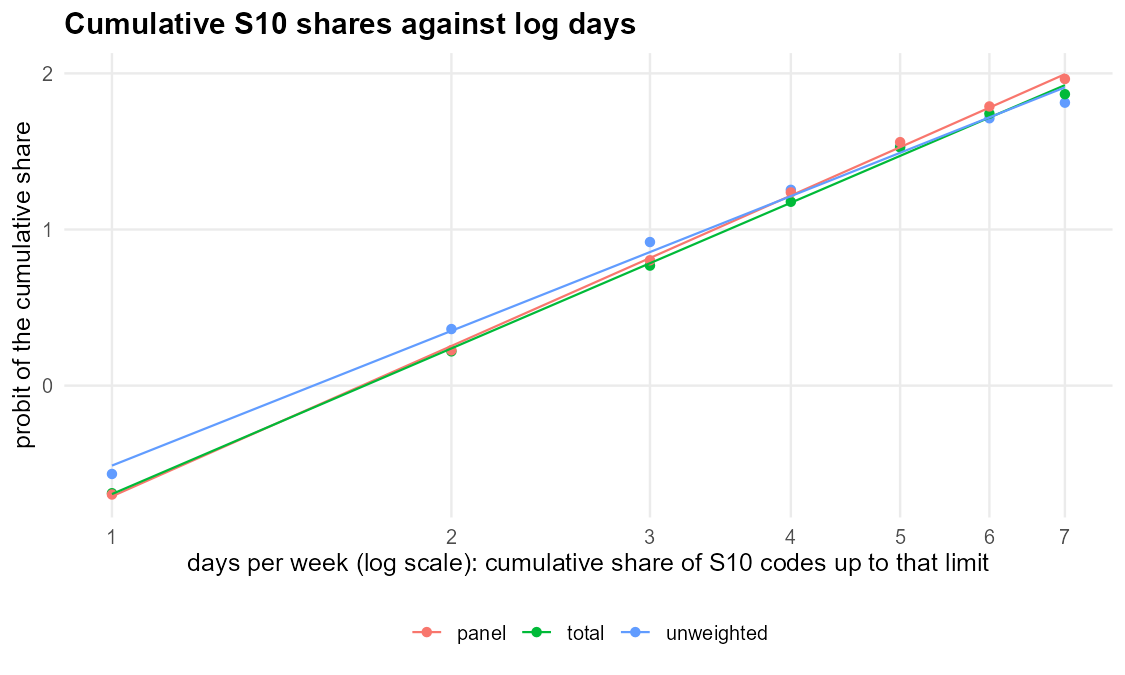

scheme,interval,n_regular_destinations,slope,implied_sigma,r_squared,r_squared_rounding,r_squared_linear_days
unweighted,All,2488,1.245,0.803,0.995,0.997,0.890
unweighted,2016-2018,762,1.230,0.813,0.992,0.998,0.878
unweighted,2018-2021,968,1.212,0.825,0.994,0.997,0.886
unweighted,2021-2023,758,1.345,0.744,0.997,0.993,0.911
total,All,2488,1.346,0.743,0.999,0.992,0.921
total,2016-2018,762,1.238,0.808,0.992,0.999,0.879
total,2018-2021,968,1.327,0.753,0.996,0.981,0.942
total,2021-2023,758,1.501,0.666,0.996,0.986,0.926
panel,All,1682,1.390,0.720,0.999,0.992,0.925
panel,2016-2018,405,1.532,0.653,0.998,0.992,0.924


scheme,interval,n_pairs,logloss_A,logloss_Lognormal,Lognormal − A [95% CI],brier_A,brier_Lognormal,logloss_Lognormal_rounding,Rounded-day reading − main reading [95% CI]
unweighted,All,5932,1.2527,1.2378,-0.0149 [-0.0208; -0.0089],0.5665,0.5624,1.2382,+0.0004 [-0.0020; +0.0027]
unweighted,2016-2018,1873,1.2189,1.2020,-0.0168 [-0.0269; -0.0067],0.5593,0.5535,1.2004,-0.0016 [-0.0055; +0.0023]
unweighted,2018-2021,2254,1.3044,1.2876,-0.0168 [-0.0267; -0.0068],0.5744,0.5711,1.2877,+0.0001 [-0.0037; +0.0040]
unweighted,2021-2023,1805,1.2233,1.2128,-0.0105 [-0.0214; +0.0005],0.5641,0.5609,1.2155,+0.0027 [-0.0011; +0.0064]
total,All,5932,1.4300,1.3962,-0.0338 [-0.0479; -0.0197],0.6371,0.6304,1.4014,+0.0052 [+0.0002; +0.0102]
total,2016-2018,1873,1.3816,1.3394,-0.0422 [-0.0647; -0.0197],0.6282,0.6167,1.3346,-0.0047 [-0.0133; +0.0038]
total,2018-2021,2254,1.4878,1.4460,-0.0419 [-0.0683; -0.0154],0.6434,0.6385,1.4589,+0.0129 [+0.0052; +0.0206]
total,2021-2023,1805,1.4097,1.3942,-0.0156 [-0.0376; +0.0064],0.6385,0.6346,1.4001,+0.0060 [-0.0017; +0.0137]
panel,All,4066,1.4968,1.4436,-0.0532 [-0.0780; -0.0283],0.6642,0.6555,1.4501,+0.0065 [-0.0002; +0.0131]
panel,2016-2018,1006,1.4963,1.4180,-0.0782 [-0.1405; -0.0160],0.6872,0.6721,1.4190,+0.0009 [-0.0109; +0.0128]


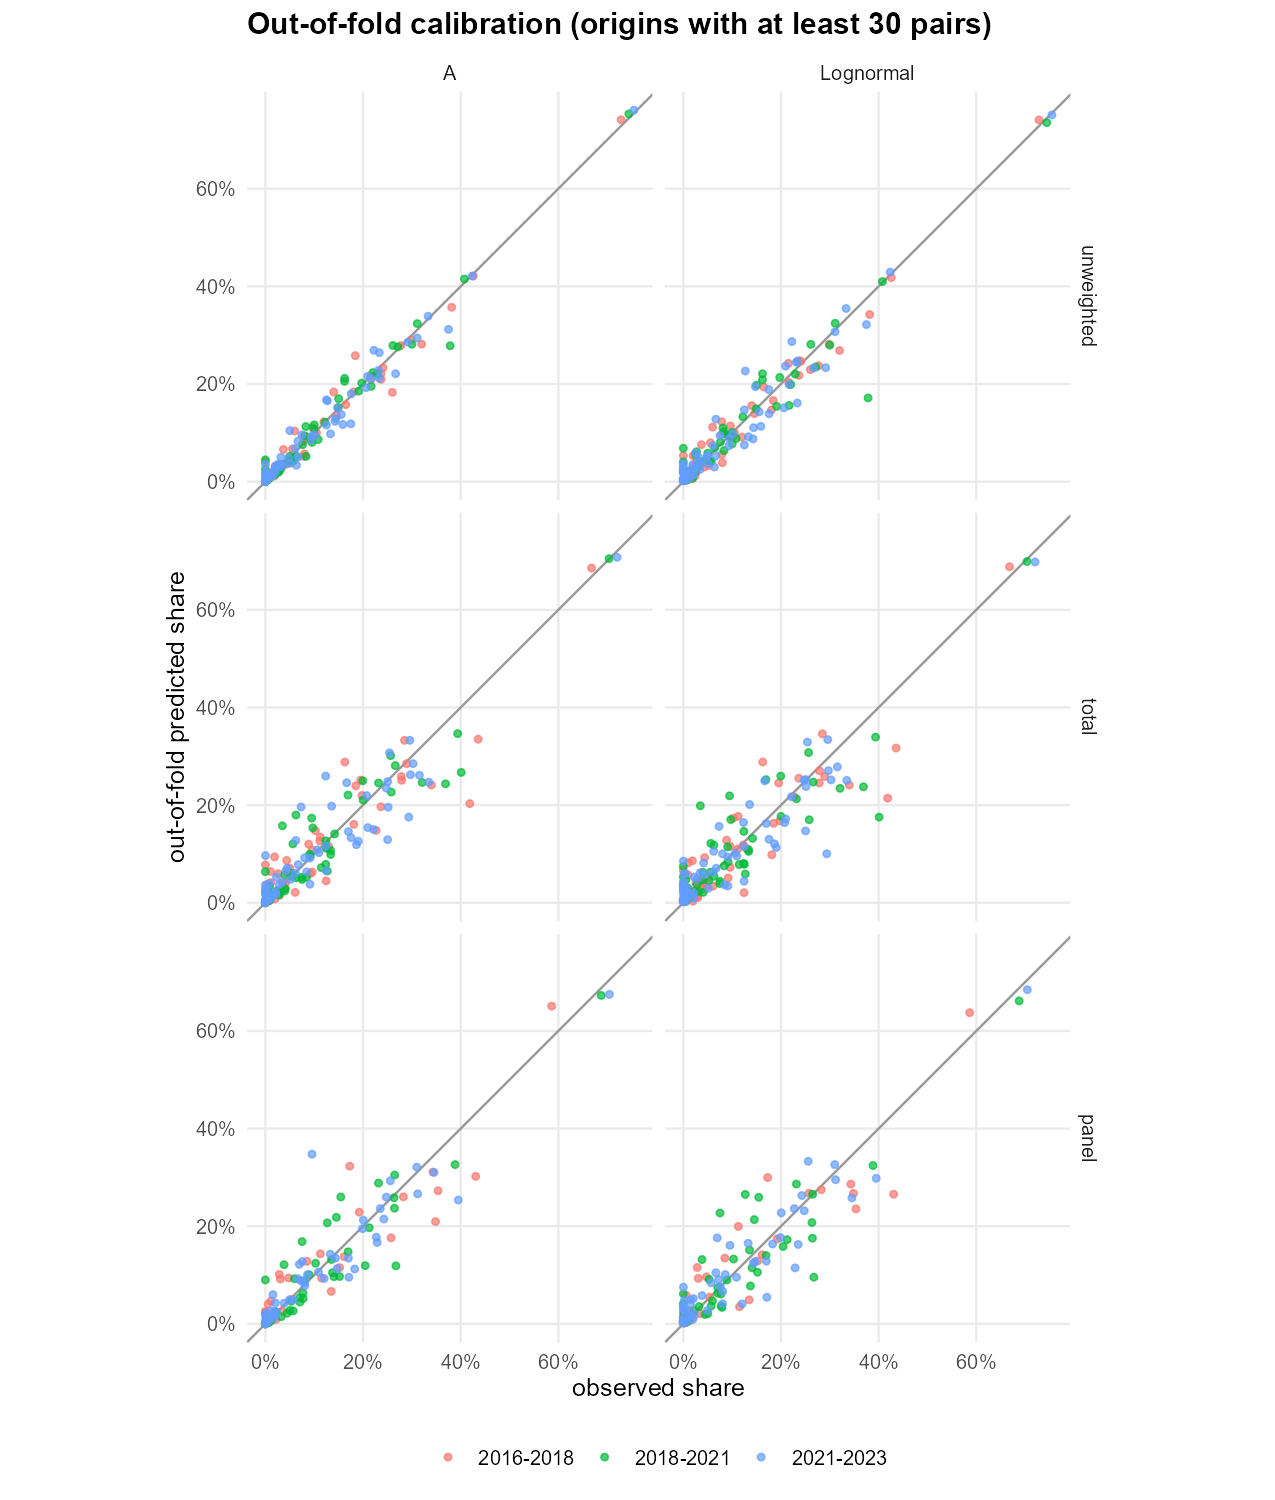

Elapsed: 0.02 minutes


In [14]:
#| label: elsoc-s-models
.t0 <- Sys.time()
tu <- stt("A_tuning"); tw <- stats::reshape(tu[, c("scheme", "k", "logloss")], idvar = "k", timevar = "scheme", direction = "wide"); names(tw) <- sub("^logloss\\.", "", names(tw))
ch <- tu[tu$chosen, c("scheme", "k")]
show_table(tw, paste0("Matrix A: person-blocked 3-fold cross-validated log loss by shrinkage strength k (EPS grid extended to 3000 and 10000); chosen k: ", paste(ch$scheme, ch$k, sep = " = ", collapse = ", ")), digits = 4)
co <- stt("lognormal_coefficients"); cw <- stats::reshape(co, idvar = c("part", "term"), timevar = "scheme", direction = "wide"); names(cw) <- sub("^estimate\\.", "", names(cw))
show_table(cw, "Two-part lognormal: coefficients of the participation logit and of log days per week, by weighting scheme (reference: origin NR, men 18–29, 2016→2018)", digits = 3)
sh <- stt("lognormal_shape")
p <- ggplot2::ggplot(sh[sh$interval == "All", ], ggplot2::aes(log(cut_days), probit, colour = scheme)) + ggplot2::geom_point() + ggplot2::geom_smooth(method = "lm", formula = y ~ x, se = FALSE, linewidth = .5) +
  ggplot2::scale_x_continuous(breaks = log(1:7), labels = 1:7) + ggplot2::labs(x = "days per week (log scale): cumulative share of S10 codes up to that limit", y = "probit of the cumulative share", colour = NULL, title = "Cumulative S10 shares against log days") + plot_theme()
show_plot_s(p, "lognormal_shape", 7.5, 4.5)
show_table(unique(sh[, c("scheme", "interval", "n_regular_destinations", "slope", "implied_sigma", "r_squared", "r_squared_rounding", "r_squared_linear_days")]),
  "Probit of the cumulative S10 distribution: slope on log days, implied lognormal sigma and R squared under the main reading (code k = k − 1 to k days), the rounded-day reading (limits 0.5 to 6.5) and a linear day scale, by scheme and interval", digits = 3)
cvc <- stt("cv_comparison"); dci <- function(d, se) sprintf("%+.4f [%+.4f; %+.4f]", d, d - 1.96 * se, d + 1.96 * se)
cvc$`Lognormal − A [95% CI]` <- dci(cvc$logloss_difference, cvc$logloss_difference_se); cvc$`Rounded-day reading − main reading [95% CI]` <- dci(cvc$rounding_minus_floor, cvc$rounding_minus_floor_se)
show_table(cvc[, c("scheme", "interval", "n_pairs", "logloss_A", "logloss_Lognormal", "Lognormal − A [95% CI]", "brier_A", "brier_Lognormal", "logloss_Lognormal_rounding", "Rounded-day reading − main reading [95% CI]")],
  "Out-of-fold comparison, 5 person-blocked folds × 3 repeats: weighted log loss and Brier score; negative differences favour the first model named. The last columns refit the lognormal reading S10 codes as days rounded to the nearest day", digits = 4)
ca <- stt("calibration_oof"); ca <- ca[ca$n_origin >= 30 & ca$model %in% c("A", "Lognormal"), ]
p <- ggplot2::ggplot(ca, ggplot2::aes(observed, predicted_out_of_fold, colour = interval)) + ggplot2::geom_abline(colour = "grey60") + ggplot2::geom_point(alpha = .7, size = 1.3) + ggplot2::facet_grid(factor(scheme, SCH) ~ factor(model, c("A", "Lognormal"))) +
  ggplot2::coord_equal() + ggplot2::scale_x_continuous(labels = scales::percent) + ggplot2::scale_y_continuous(labels = scales::percent) +
  ggplot2::labs(x = "observed share", y = "out-of-fold predicted share", colour = NULL, title = "Out-of-fold calibration (origins with at least 30 pairs)") + plot_theme()
show_plot_s(p, "calibration_oof", 8.5, 10)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


### All pairs: the nine-state matrices

One figure per weighting scheme shows the three estimators side by side for all pairs of each interval and for the pooled data, with percentages in each cell. Rows of three days or more almost never reach 30 pairs in an interval and stratum, and many rows of less than one day to two days do not either, so the observed rows are noisy. Matrix A keeps each origin's pattern but, under the weights, replaces it with the row of all intervals. The lognormal smooths across neighbouring categories: it underestimates staying at the common frequencies, less than one day to two days a week and daily, and overestimates it at four to six days, where staying is almost never observed.


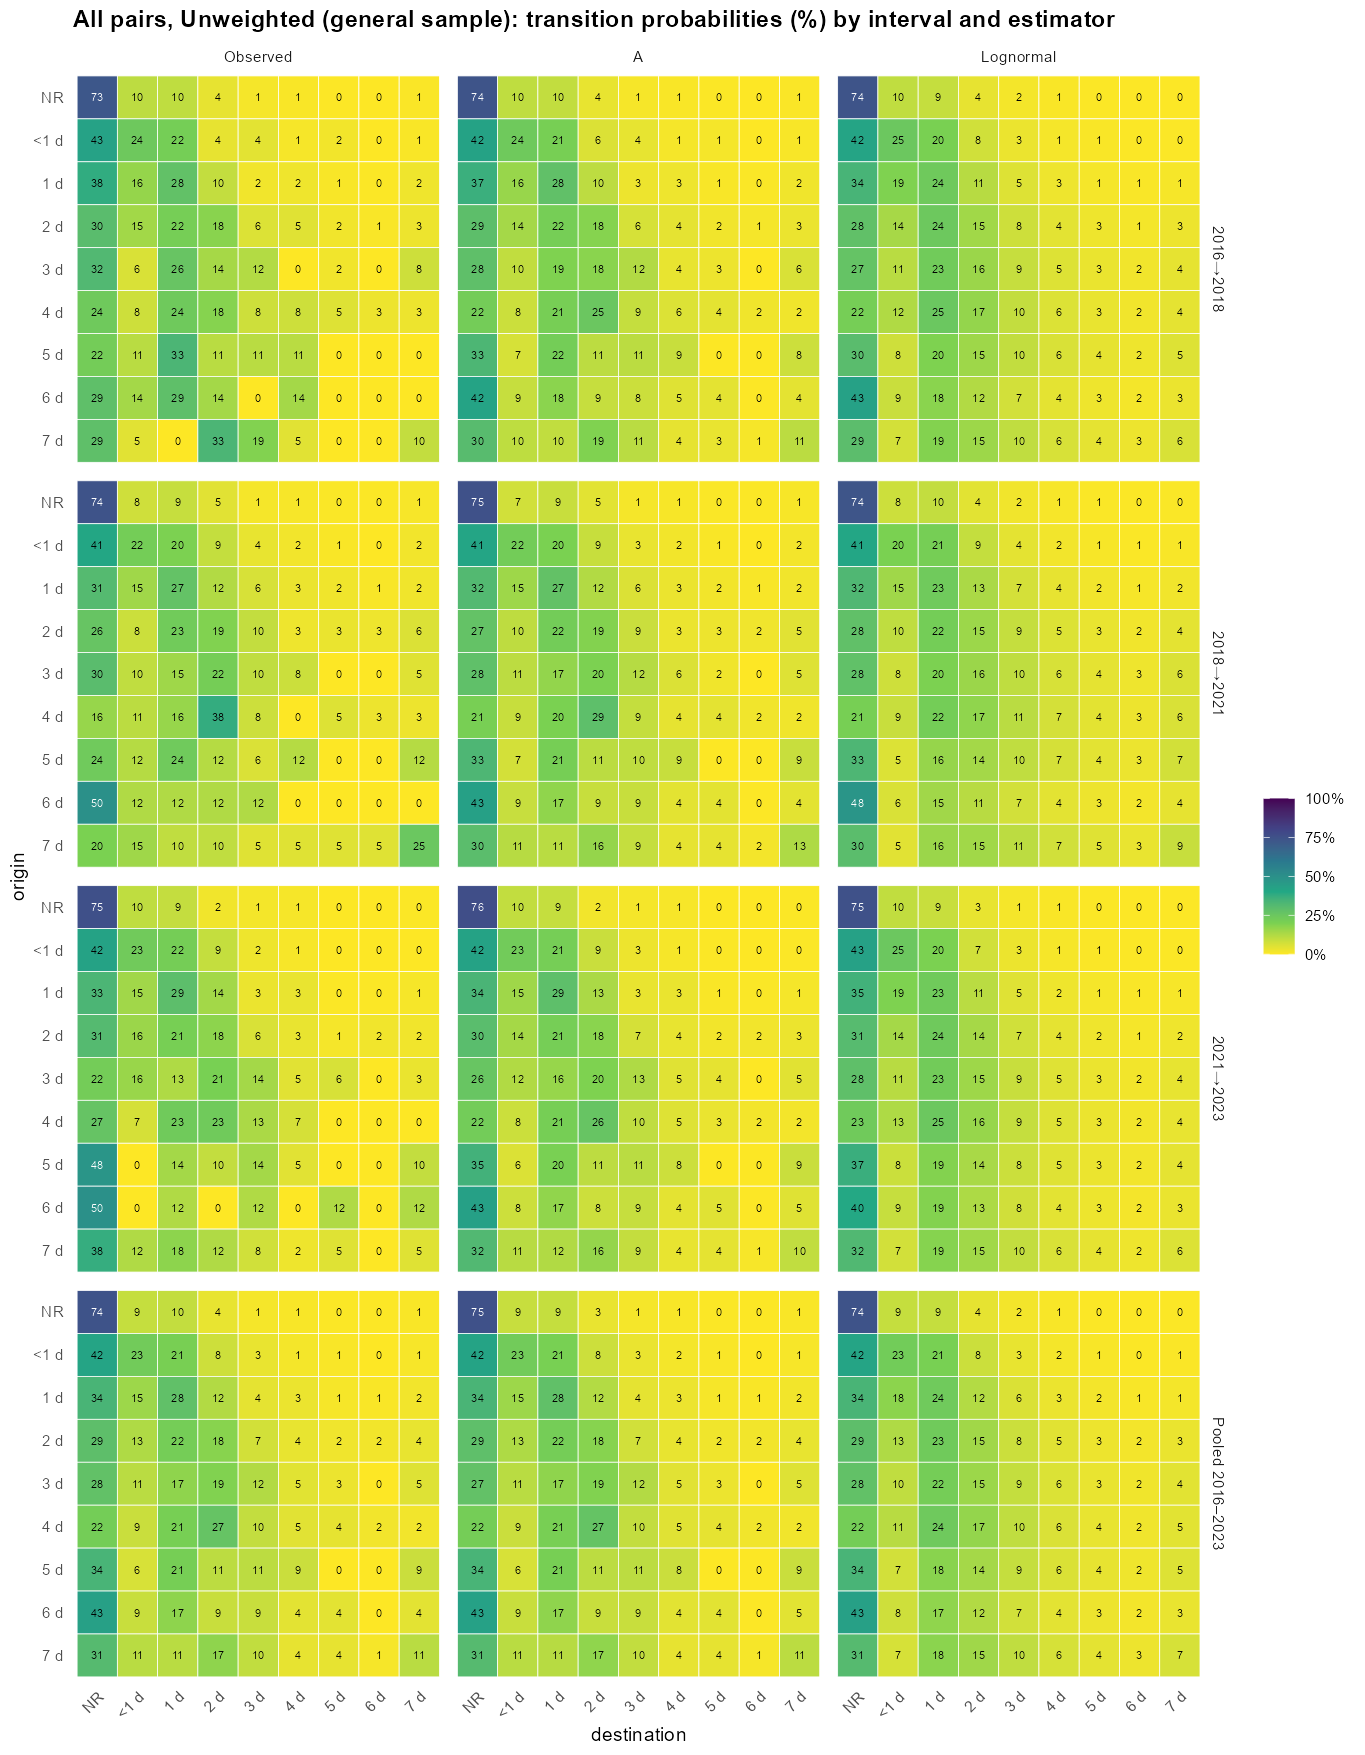

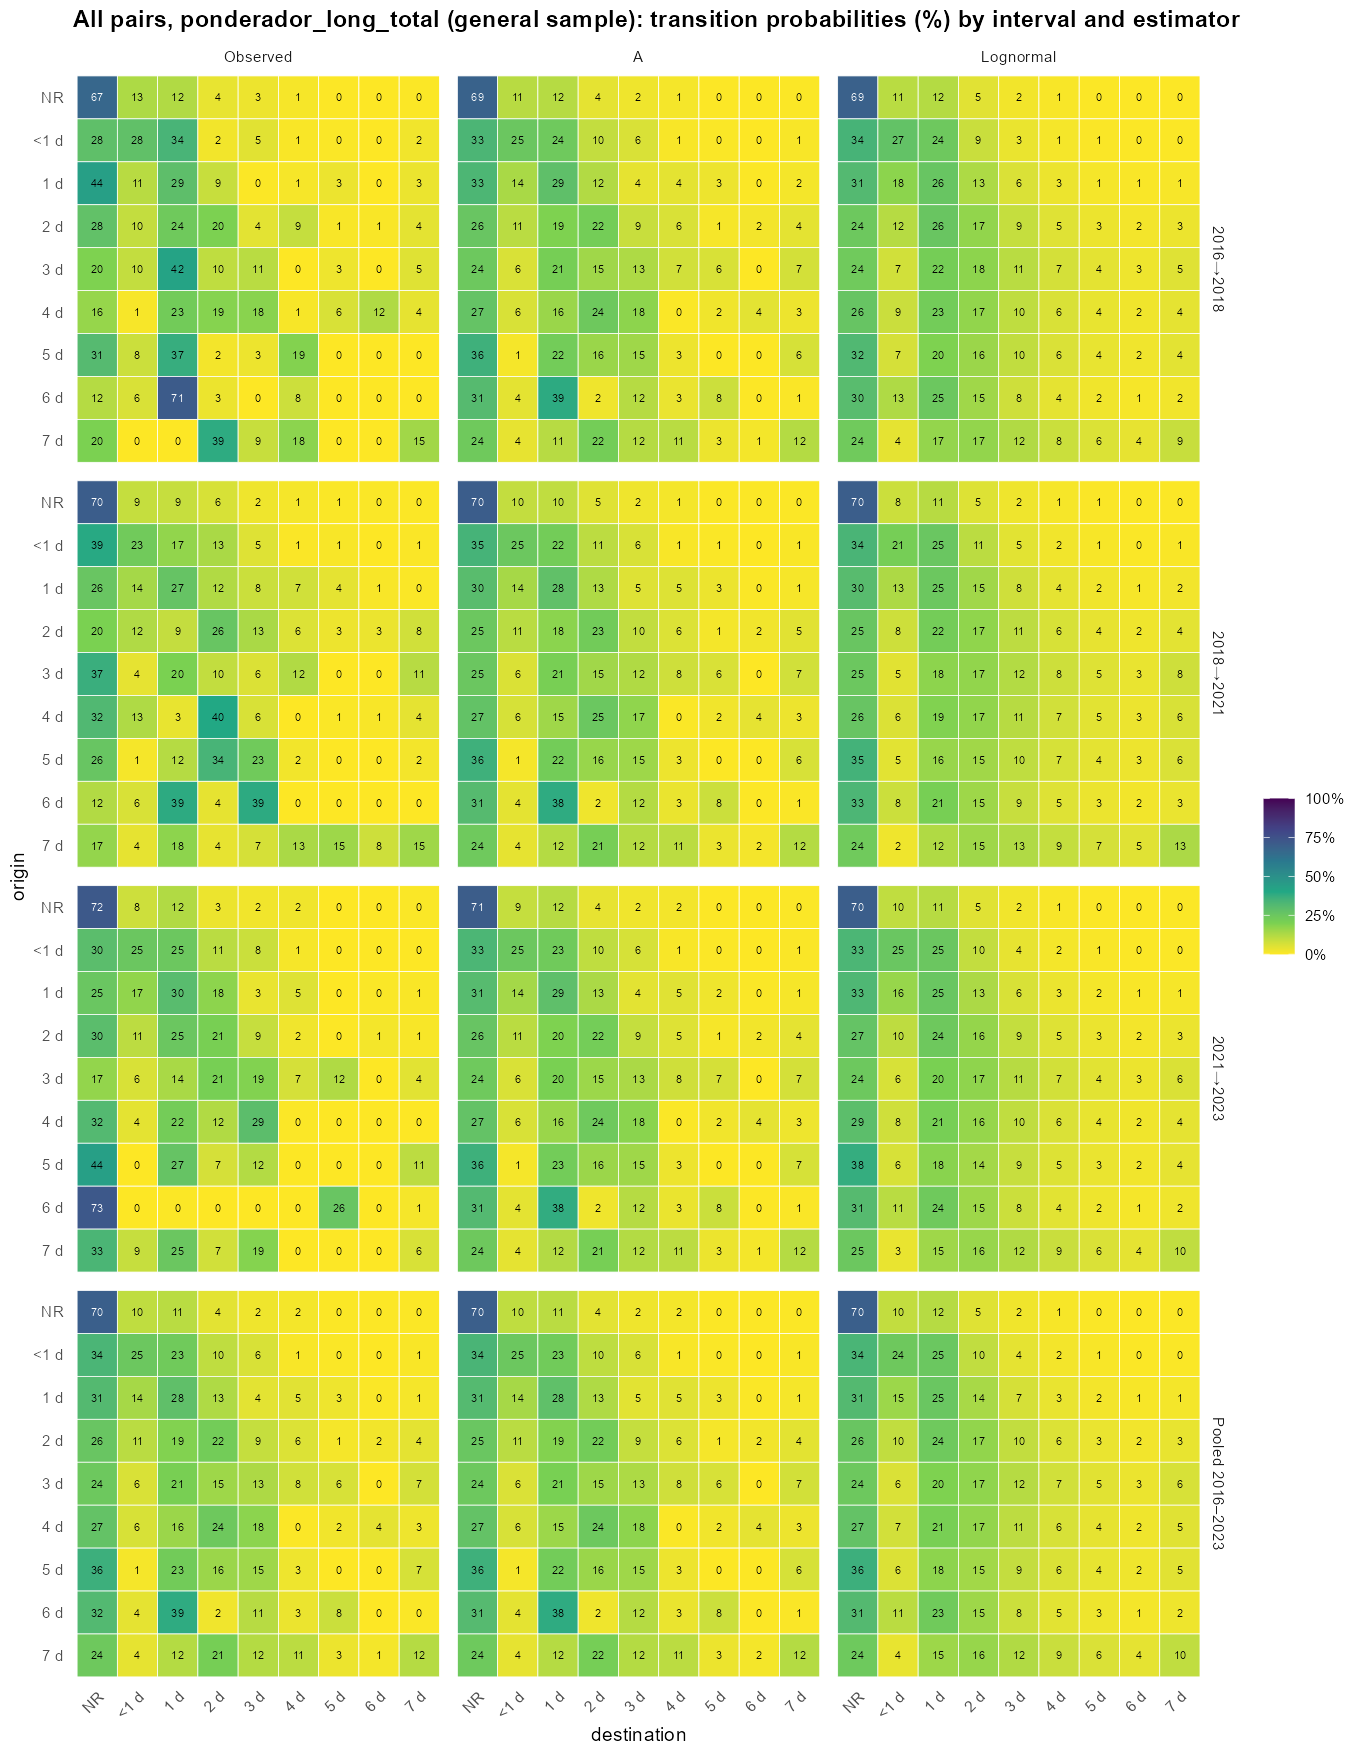

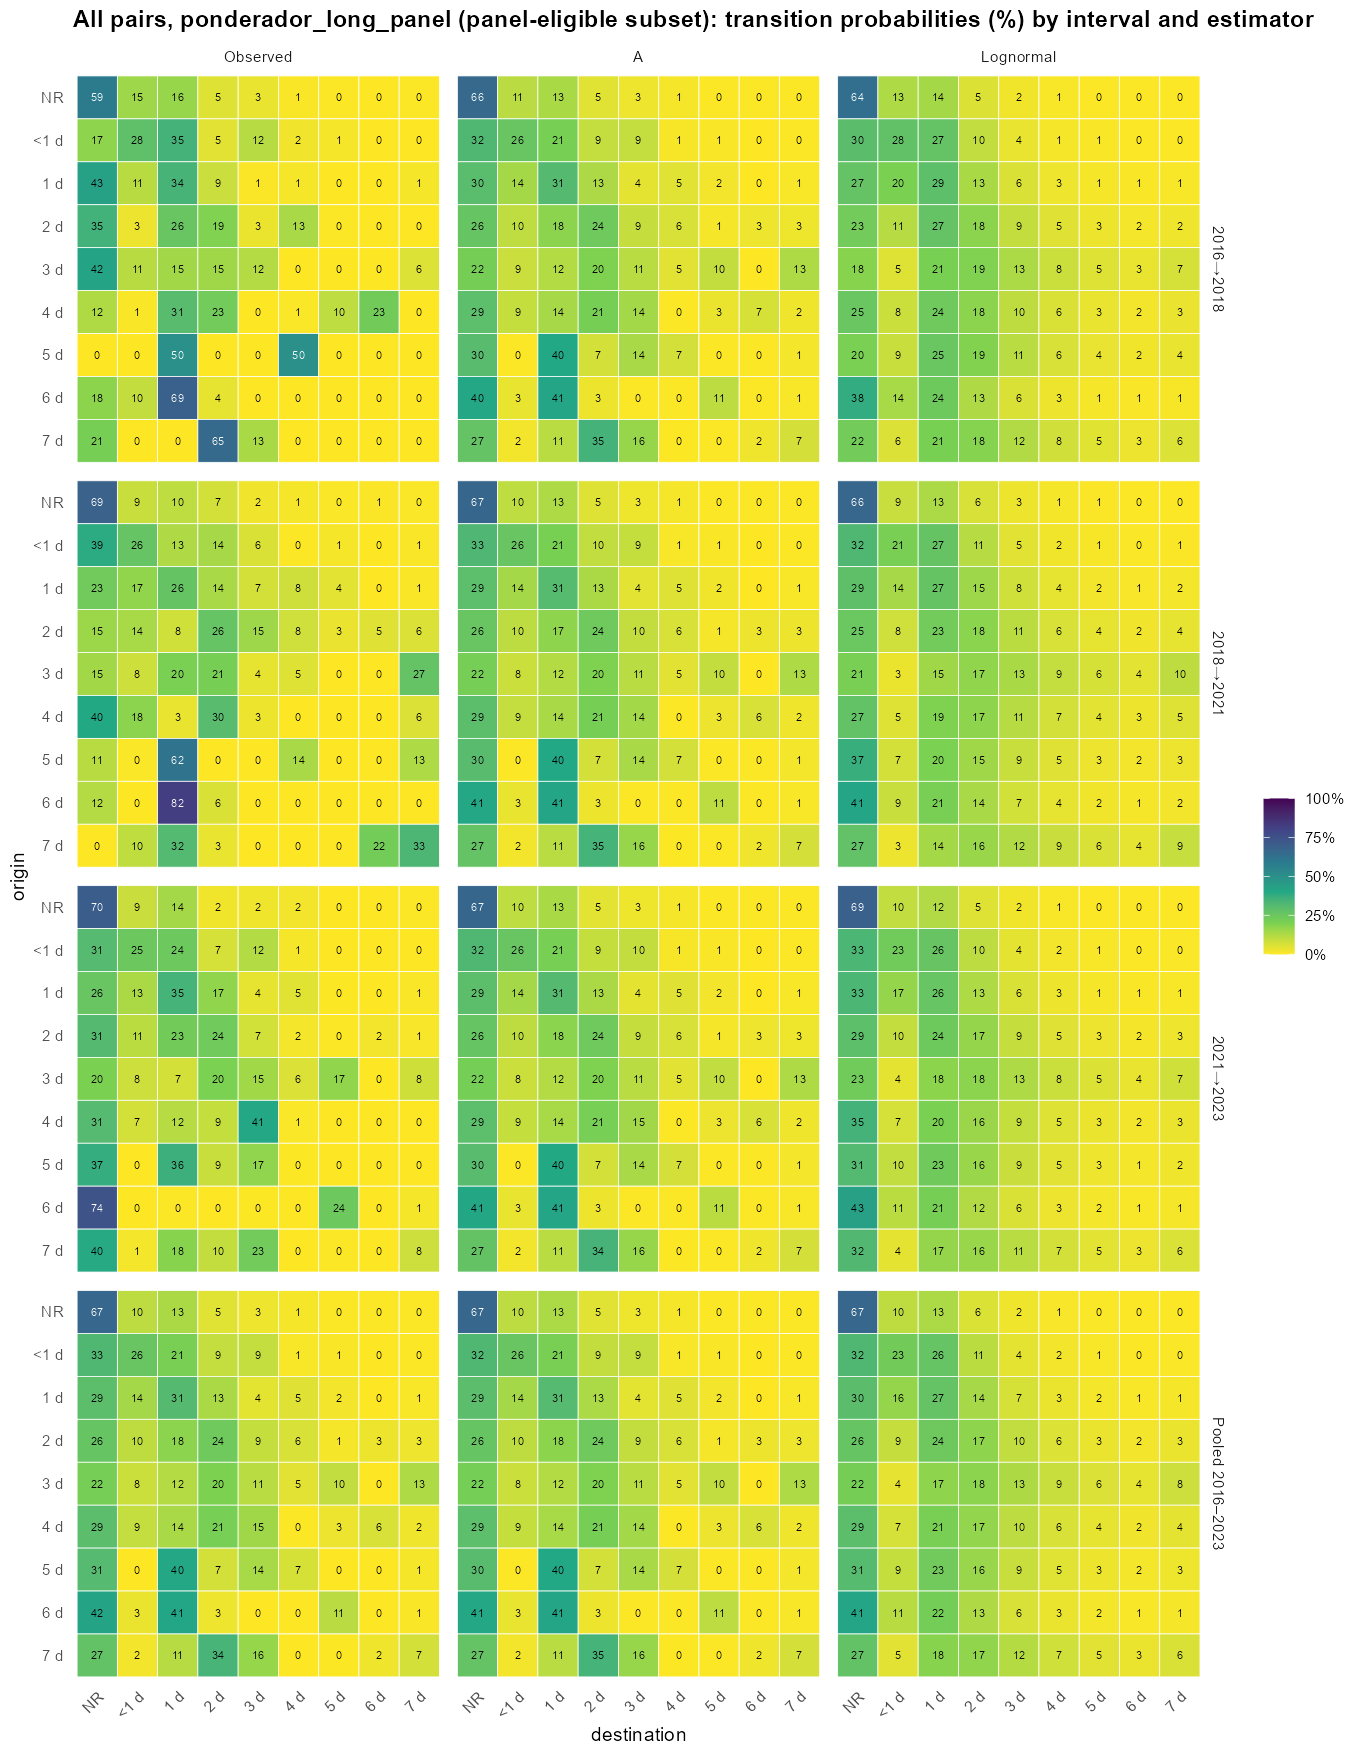

Elapsed: 0.03 minutes


In [15]:
#| label: elsoc-s-all
.t0 <- Sys.time()
heat <- function(z, title) ggplot2::ggplot(z, ggplot2::aes(factor(to, ST, st_short[ST]), factor(from, rev(ST), st_short[rev(ST)]), fill = estimate)) + ggplot2::geom_tile(colour = "white") +
  ggplot2::geom_text(ggplot2::aes(label = ifelse(is.na(estimate), "", sprintf("%.0f", 100 * estimate)), colour = !is.na(estimate) & estimate > .45), size = 2.2) +
  ggplot2::scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "black"), guide = "none") + ggplot2::scale_fill_viridis_c(direction = -1, limits = c(0, 1), na.value = "grey92", labels = scales::percent) +
  ggplot2::facet_grid(factor(level, LV, lv_label[LV]) ~ factor(estimator, EST)) + ggplot2::labs(x = "destination", y = "origin", fill = NULL, title = title) + ggplot2::theme_minimal(base_size = 11) +
  ggplot2::theme(panel.grid = ggplot2::element_blank(), plot.title = ggplot2::element_text(face = "bold"), axis.text.x = ggplot2::element_text(angle = 45, hjust = 1))
for (s in SCH) show_plot_s(heat(SM[SM$group == "All" & SM$scheme == s, ], paste0("All pairs, ", sch_label[s], ": transition probabilities (%) by interval and estimator")), paste0("heat_all_", s), 10.5, 13.5, dpi = 130)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


### By sex, initial age and origin wave

Each block opens one stratum and shows the matrix under the three weights. In each cell the first line is the observed survey-weighted percentage with its 95% segment-bootstrap interval, and the purple line gives the matrix A and lognormal estimates; hovering over that line shows their intervals. The n column is the unweighted number of pairs from that origin, and rows marked with an asterisk have fewer than 30. An origin with no pairs shows a dash for the observed estimator while the models still give a smoothed row, which is a model extrapolation. Only the observed estimator gives sex × age patterns specific to a wave. The lognormal applies the same sex × age and origin effects in every wave, shifted by an interval term as in the EPS specification, and matrix A under the weights is practically one matrix, so differences between waves within a stratum should be read from the observed lines. Every number is in `intervals/states_matrices.csv`, with the bootstrap interval for every estimator, the strata + segments Taylor interval for observed rows and, for pooled observed rows, the person-clustered Taylor interval.


In [16]:
#| label: elsoc-s-strata
.t0 <- Sys.time()
st_css <- "<style>details.stm{border:1px solid #d6dbe2;border-radius:6px;margin:6px 0;padding:4px 10px}details.stm summary{cursor:pointer;padding:4px 0}table.stm-t{border-collapse:collapse;font-size:12px;font-variant-numeric:tabular-nums;margin:4px 0 12px}table.stm-t th,table.stm-t td{border:1px solid #e3e7ec;padding:3px 5px;text-align:center;vertical-align:top}table.stm-t td.d{background:#eef4fb}table.stm-t tr.sp th,table.stm-t tr.sp td{color:#7d8791}table.stm-t small{color:#5a6572}table.stm-t span.m{display:block;color:#6b4c9a;font-size:11px;white-space:nowrap}p.stm-h{font-weight:600;margin:8px 0 2px}p.stm-lv{font-size:1.1em;font-weight:700;margin:14px 0 4px}</style>"
mat_table <- function(z) {   # one scheme x level x group, the three estimators
  pick <- function(est) { x <- z[z$estimator == est, ]; x[match(paste(rep(ST, each = 9), rep(ST, 9)), paste(x$from, x$to)), ] }
  ob <- pick("Observed"); a <- pick("A"); ln <- pick("Lognormal")
  head <- paste0("<tr><th>From ↓ to →</th><th>n</th>", paste0("<th>", st_short[ST], "</th>", collapse = ""), "</tr>")
  body <- vapply(seq_len(9), function(i) { r <- (i - 1) * 9 + 1:9; n <- ob$n_origin[r[1]]
    tip <- sprintf("A %s [%s; %s] | lognormal %s [%s; %s]", pc1(a$estimate[r]), pc1(a$lower[r]), pc1(a$upper[r]), pc1(ln$estimate[r]), pc1(ln$lower[r]), pc1(ln$upper[r]))
    obs <- if (n > 0) paste0(pc1(ob$estimate[r]), ifelse(is.na(ob$lower[r]), "", sprintf("<br><small>[%s; %s]</small>", pc1(ob$lower[r]), pc1(ob$upper[r])))) else rep("—", 9)
    cells <- sprintf("<td%s>%s<span class=\"m\" title=\"%s\">A %s · LN %s</span></td>", ifelse(seq_len(9) == i, " class=\"d\"", ""), obs, tip, pc1(a$estimate[r]), pc1(ln$estimate[r]))
    sprintf("<tr%s><th>%s</th><td>%d%s</td>%s</tr>", if (n < 30) " class=\"sp\"" else "", st_short[ST[i]], n, if (n < 30) "*" else "", paste(cells, collapse = "")) }, "")
  paste0("<div style=\"overflow-x:auto\"><table class=\"stm-t\">", head, paste(body, collapse = ""), "</table></div>")
}
block <- function(lv, g) { z <- SM[SM$level == lv & SM$group == g, ]; s0 <- SST[SST$level == lv & SST$group == g, ]
  su <- s0[s0$scheme == "unweighted", ]; tt <- s0[s0$scheme == "total", ]; sp <- s0[s0$scheme == "panel", ]
  head <- sprintf("<summary><b>%s</b> · %d pairs · %d persons · ESS %.0f with ponderador_long_total · panel subset %d pairs, ESS %.0f</summary>", group_label(g), su$n_pairs, su$n_persons, tt$ess, sp$n_pairs, sp$ess)
  paste0("<details class=\"stm\">", head, paste(vapply(SCH, function(s) paste0("<p class=\"stm-h\">", sch_label[s], "</p>", mat_table(z[z$scheme == s, ])), ""), collapse = ""), "</details>") }
IRdisplay::display_html(st_css)
for (lv in LV[1:3]) IRdisplay::display_html(paste0("<p class=\"stm-lv\">Origin wave ", substr(lv, 1, 4), ": ", lv_label[lv], "</p>", paste(vapply(c("All", SA), function(g) block(lv, g), ""), collapse = "")))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d
NR,1193,72.8[70.2; 75.7]A 73.9 · LN 74.1,10.5[8.7; 12.4]A 10.2 · LN 10.0,10.1[8.5; 11.9]A 9.7 · LN 9.2,3.7[2.6; 4.8]A 3.5 · LN 3.7,1.3[0.7; 2.0]A 1.2 · LN 1.5,0.7[0.2; 1.2]A 0.6 · LN 0.7,0.3[0.0; 0.6]A 0.3 · LN 0.3,0.0A 0.0 · LN 0.2,0.6[0.2; 1.0]A 0.6 · LN 0.2
<1 d,162,42.6[34.5; 49.7]A 42.4 · LN 41.8,24.1[17.4; 31.0]A 23.7 · LN 24.8,21.6[16.1; 27.6]A 21.1 · LN 20.3,3.7[1.2; 6.7]A 5.7 · LN 7.5,4.3[1.4; 7.8]A 3.6 · LN 3.0,1.2[0.0; 3.2]A 1.3 · LN 1.3,1.9[0.0; 4.1]A 1.4 · LN 0.6,0.0A 0.0 · LN 0.3,0.6[0.0; 2.0]A 0.8 · LN 0.4
1 d,249,38.2[31.8; 44.7]A 36.7 · LN 34.2,16.5[11.7; 21.5]A 16.0 · LN 19.4,27.7[22.3; 33.3]A 28.0 · LN 23.7,9.6[6.1; 13.5]A 10.5 · LN 11.4,2.0[0.4; 3.8]A 2.7 · LN 5.3,2.4[0.4; 4.8]A 2.6 · LN 2.6,0.8[0.0; 2.0]A 0.9 · LN 1.4,0.4[0.0; 1.3]A 0.5 · LN 0.8,2.4[0.8; 4.5]A 2.2 · LN 1.2
2 d,144,29.9[23.0; 37.4]A 29.0 · LN 28.1,14.6[8.9; 20.7]A 14.2 · LN 13.9,21.5[15.0; 28.5]A 21.6 · LN 24.2,18.1[12.1; 24.4]A 18.4 · LN 14.7,5.6[2.2; 9.5]A 6.4 · LN 8.0,4.9[1.5; 8.5]A 4.1 · LN 4.4,2.1[0.0; 4.7]A 2.0 · LN 2.5,0.7[0.0; 2.2]A 1.3 · LN 1.5,2.8[0.6; 5.9]A 3.0 · LN 2.7
3 d,50,32.0[20.0; 45.7]A 28.5 · LN 26.7,6.0[0.0; 13.3]A 9.8 · LN 11.1,26.0[13.9; 39.4]A 19.4 · LN 22.9,14.0[5.6; 24.5]A 17.9 · LN 15.6,12.0[3.8; 21.3]A 12.2 · LN 9.2,0.0A 3.5 · LN 5.3,2.0[0.0; 6.7]A 2.7 · LN 3.2,0.0A 0.0 · LN 2.0,8.0[1.9; 16.0]A 6.0 · LN 3.9
4 d,38,23.7[9.1; 40.0]A 22.2 · LN 21.5,7.9[0.0; 17.2]A 8.3 · LN 12.4,23.7[10.4; 39.1]A 21.2 · LN 24.9,18.4[6.7; 31.6]A 25.1 · LN 16.6,7.9[0.0; 17.9]A 9.2 · LN 9.6,7.9[0.0; 17.9]A 5.5 · LN 5.6,5.3[0.0; 13.2]A 4.1 · LN 3.3,2.6[0.0; 8.8]A 2.1 · LN 2.0,2.6[0.0; 8.9]A 2.1 · LN 4.0
5 d,9*,22.2A 33.0 · LN 30.0,11.1A 6.5 · LN 7.8,33.3A 22.0 · LN 19.5,11.1A 10.7 · LN 15.2,11.1A 10.7 · LN 9.7,11.1A 8.7 · LN 6.1,0.0A 0.1 · LN 3.8,0.0A 0.1 · LN 2.5,0.0A 8.1 · LN 5.4
6 d,7*,28.6A 41.9 · LN 42.7,14.3A 9.1 · LN 8.6,28.6A 17.8 · LN 17.9,14.3A 9.0 · LN 12.3,0.0A 8.3 · LN 7.2,14.3A 5.0 · LN 4.2,0.0A 4.3 · LN 2.5,0.0A 0.2 · LN 1.5,0.0A 4.3 · LN 3.1
7 d,21*,28.6[10.0; 50.0]A 30.3 · LN 29.4,4.8[0.0; 15.0]A 10.3 · LN 7.1,0.0A 9.9 · LN 18.8,33.3[14.3; 54.5]A 19.2 · LN 15.3,19.0[4.0; 37.5]A 11.0 · LN 10.1,4.8[0.0; 15.4]A 3.9 · LN 6.4,0.0A 3.3 · LN 4.1,0.0A 1.1 · LN 2.7,9.5[0.0; 24.1]A 10.9 · LN 6.1
From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d


From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d
NR,1318,74.4[72.1; 76.6]A 75.2 · LN 73.6,7.6[6.2; 9.1]A 7.4 · LN 8.1,9.0[7.6; 10.5]A 8.8 · LN 9.6,4.8[3.7; 5.9]A 4.6 · LN 4.5,1.4[0.8; 2.0]A 1.3 · LN 2.1,1.0[0.5; 1.6]A 1.0 · LN 1.0,0.5[0.1; 0.9]A 0.5 · LN 0.5,0.4[0.1; 0.7]A 0.3 · LN 0.3,1.0[0.5; 1.5]A 0.9 · LN 0.4
<1 d,309,40.8[35.0; 46.3]A 41.3 · LN 40.9,22.0[17.5; 26.5]A 22.2 · LN 20.0,19.7[15.4; 24.4]A 20.0 · LN 21.4,9.4[6.2; 12.5]A 8.9 · LN 9.4,3.6[1.6; 5.7]A 3.4 · LN 4.1,1.9[0.6; 3.6]A 1.8 · LN 1.9,0.6[0.0; 1.6]A 0.7 · LN 1.0,0.0A 0.0 · LN 0.5,1.9[0.6; 3.7]A 1.7 · LN 0.8
1 d,328,31.1[26.2; 35.9]A 31.7 · LN 32.4,14.9[11.0; 19.0]A 15.2 · LN 14.9,27.1[22.1; 32.4]A 27.4 · LN 23.5,12.2[8.8; 15.9]A 12.2 · LN 13.3,6.4[3.9; 9.3]A 5.7 · LN 6.9,3.0[1.5; 5.1]A 3.0 · LN 3.7,2.1[0.7; 3.8]A 1.9 · LN 2.1,0.9[0.0; 2.0]A 0.8 · LN 1.2,2.1[0.6; 3.9]A 2.1 · LN 2.1
2 d,157,26.1[19.4; 32.9]A 27.2 · LN 28.1,8.3[4.2; 12.8]A 10.3 · LN 10.2,22.9[16.7; 29.7]A 22.3 · LN 22.0,19.1[13.3; 25.4]A 18.8 · LN 15.4,9.6[5.4; 14.2]A 8.5 · LN 9.2,2.5[0.6; 5.5]A 3.1 · LN 5.5,3.2[0.7; 6.2]A 2.7 · LN 3.3,2.5[0.6; 5.3]A 2.3 · LN 2.1,5.7[2.5; 9.6]A 4.7 · LN 4.2
3 d,60,30.0[19.0; 41.6]A 28.3 · LN 27.9,10.0[3.3; 17.5]A 10.7 · LN 7.7,15.0[6.4; 24.6]A 16.7 · LN 19.8,21.7[11.8; 32.6]A 19.8 · LN 15.6,10.0[3.3; 18.9]A 11.5 · LN 10.1,8.3[2.0; 15.9]A 5.7 · LN 6.4,0.0A 2.1 · LN 4.0,0.0A 0.0 · LN 2.6,5.0[0.0; 11.3]A 5.2 · LN 5.9
4 d,37,16.2[5.4; 29.0]A 20.8 · LN 21.1,10.8[2.4; 22.2]A 8.9 · LN 8.8,16.2[4.9; 29.6]A 20.0 · LN 22.0,37.8[22.2; 53.7]A 28.8 · LN 17.1,8.1[0.0; 17.9]A 9.4 · LN 11.0,0.0A 3.9 · LN 6.8,5.4[0.0; 13.8]A 4.1 · LN 4.3,2.7[0.0; 9.1]A 2.0 · LN 2.8,2.7[0.0; 9.1]A 2.1 · LN 6.1
5 d,17*,23.5[5.6; 46.2]A 32.9 · LN 32.8,11.8[0.0; 30.0]A 6.9 · LN 5.5,23.5[5.6; 46.7]A 21.4 · LN 16.4,11.8[0.0; 30.0]A 10.8 · LN 14.3,5.9[0.0; 20.0]A 10.2 · LN 10.0,11.8[0.0; 30.0]A 8.9 · LN 6.6,0.0A 0.1 · LN 4.4,0.0A 0.1 · LN 2.9,11.8[0.0; 28.6]A 8.8 · LN 7.1
6 d,8*,50.0A 43.1 · LN 47.9,12.5A 9.0 · LN 6.0,12.5A 17.1 · LN 14.8,12.5A 8.9 · LN 11.3,12.5A 8.9 · LN 7.2,0.0A 4.3 · LN 4.4,0.0A 4.3 · LN 2.8,0.0A 0.2 · LN 1.8,0.0A 4.3 · LN 3.9
7 d,20*,20.0[4.5; 39.2]A 29.6 · LN 29.8,15.0[0.0; 33.3]A 11.4 · LN 4.7,10.0[0.0; 26.3]A 11.1 · LN 15.6,10.0[0.0; 25.0]A 16.4 · LN 14.7,5.0[0.0; 16.7]A 9.3 · LN 10.7,5.0[0.0; 17.4]A 3.8 · LN 7.3,5.0[0.0; 17.6]A 3.9 · LN 5.0,5.0[0.0; 17.2]A 1.7 · LN 3.4,25.0[7.7; 45.8]A 12.8 · LN 8.9
From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d


From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d
NR,1028,75.5[72.9; 78.1]A 76.3 · LN 75.1,10.1[8.4; 11.9]A 9.7 · LN 9.8,9.4[7.7; 11.3]A 9.3 · LN 8.8,1.9[1.2; 2.8]A 1.9 · LN 3.5,1.5[0.8; 2.3]A 1.4 · LN 1.4,1.2[0.5; 1.9]A 1.0 · LN 0.6,0.1[0.0; 0.3]A 0.1 · LN 0.3,0.0A 0.0 · LN 0.2,0.3[0.0; 0.7]A 0.3 · LN 0.2
<1 d,203,42.4[35.2; 49.8]A 42.3 · LN 42.8,23.2[17.2; 29.1]A 22.9 · LN 24.7,21.7[16.1; 27.8]A 21.4 · LN 19.9,9.4[5.5; 13.6]A 8.6 · LN 7.3,2.5[0.5; 4.8]A 2.8 · LN 2.8,1.0[0.0; 2.5]A 1.2 · LN 1.2,0.0A 0.3 · LN 0.6,0.0A 0.0 · LN 0.3,0.0A 0.4 · LN 0.4
1 d,264,33.3[27.7; 39.2]A 33.8 · LN 35.5,14.8[10.8; 19.1]A 15.0 · LN 19.5,29.2[23.8; 34.7]A 28.8 · LN 23.3,14.4[10.4; 19.0]A 13.3 · LN 11.0,3.0[1.2; 5.3]A 3.3 · LN 5.1,3.4[1.4; 5.6]A 3.2 · LN 2.5,0.4[0.0; 1.2]A 0.6 · LN 1.3,0.4[0.0; 1.2]A 0.5 · LN 0.7,1.1[0.0; 2.6]A 1.4 · LN 1.1
2 d,148,31.1[23.8; 38.7]A 29.8 · LN 30.7,15.5[9.7; 21.6]A 14.1 · LN 14.2,20.9[14.6; 27.6]A 21.5 · LN 23.6,17.6[10.9; 24.2]A 17.9 · LN 13.9,6.1[2.6; 10.2]A 6.7 · LN 7.4,3.4[0.7; 6.6]A 3.5 · LN 4.0,1.4[0.0; 3.5]A 1.8 · LN 2.3,2.0[0.0; 4.5]A 1.9 · LN 1.3,2.0[0.0; 4.6]A 2.8 · LN 2.4
3 d,63,22.2[12.1; 32.8]A 25.9 · LN 28.4,15.9[7.2; 25.4]A 12.4 · LN 11.3,12.7[5.3; 21.2]A 16.1 · LN 22.7,20.6[10.9; 31.0]A 19.5 · LN 15.2,14.3[6.2; 23.2]A 12.6 · LN 8.8,4.8[0.0; 10.4]A 4.9 · LN 5.1,6.3[1.4; 13.1]A 3.9 · LN 3.0,0.0A 0.0 · LN 1.8,3.2[0.0; 8.2]A 4.6 · LN 3.6
4 d,30,26.7[11.5; 43.2]A 22.5 · LN 23.4,6.7[0.0; 16.0]A 8.4 · LN 12.7,23.3[9.1; 40.0]A 21.3 · LN 24.7,23.3[9.4; 39.3]A 26.1 · LN 16.1,13.3[3.0; 26.5]A 10.0 · LN 9.2,6.7[0.0; 17.2]A 5.1 · LN 5.3,0.0A 3.3 · LN 3.1,0.0A 1.7 · LN 1.9,0.0A 1.7 · LN 3.6
5 d,21*,47.6[27.8; 69.2]A 35.3 · LN 36.8,0.0A 5.7 · LN 8.4,14.3[0.0; 31.6]A 20.5 · LN 18.9,9.5[0.0; 22.2]A 10.5 · LN 13.6,14.3[0.0; 30.4]A 11.0 · LN 8.3,4.8[0.0; 16.0]A 8.1 · LN 5.0,0.0A 0.1 · LN 3.1,0.0A 0.1 · LN 1.9,9.5[0.0; 23.1]A 8.6 · LN 4.0
6 d,8*,50.0A 43.3 · LN 39.8,0.0A 8.2 · LN 9.1,12.5A 17.0 · LN 18.9,0.0A 8.2 · LN 12.9,12.5A 9.0 · LN 7.5,0.0A 4.2 · LN 4.4,12.5A 4.9 · LN 2.6,0.0A 0.2 · LN 1.6,12.5A 5.1 · LN 3.2
7 d,40,37.5[22.5; 53.8]A 31.9 · LN 32.2,12.5[2.7; 23.8]A 11.4 · LN 7.2,17.5[6.2; 30.6]A 12.4 · LN 18.5,12.5[2.8; 24.0]A 16.4 · LN 14.7,7.5[0.0; 16.1]A 9.4 · LN 9.5,2.5[0.0; 8.8]A 3.5 · LN 6.0,5.0[0.0; 12.8]A 4.0 · LN 3.8,0.0A 1.0 · LN 2.5,5.0[0.0; 12.5]A 9.9 · LN 5.6
From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d


Elapsed: 0.01 minutes


### Pooled over the three intervals

The same blocks for the pooled data come first. The tables that follow give the survey-weighted probabilities of staying non-regular, entering regular use at low frequency, leaving regular use from the three most common frequencies and keeping the same low frequency, with three 95% intervals that all keep a person's pairs together: the segment bootstrap, the Taylor interval with strata and segments, and the Taylor interval clustered by person. The ratio table compares the three standard errors and adds the one that treats pairs as independent: clustering by person is the right assumption and is kept, but it changes the standard errors little, most in staying non-regular over all pairs, the row in which the same persons repeat most. The figure sets the observed estimates beside the two models. These rows mix the three interval durations, as explained above.


From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d
NR,3539,74.2[72.7; 75.7]A 75.1 · LN 74.2,9.3[8.3; 10.3]A 9.0 · LN 9.2,9.5[8.6; 10.5]A 9.3 · LN 9.2,3.6[3.0; 4.2]A 3.4 · LN 3.9,1.4[1.0; 1.8]A 1.3 · LN 1.7,0.9[0.6; 1.3]A 0.9 · LN 0.8,0.3[0.1; 0.5]A 0.3 · LN 0.4,0.1[0.0; 0.3]A 0.1 · LN 0.2,0.6[0.4; 0.9]A 0.6 · LN 0.3
<1 d,674,41.7[37.3; 45.9]A 41.9 · LN 41.7,22.8[19.3; 26.2]A 22.8 · LN 22.6,20.8[17.9; 24.0]A 20.7 · LN 20.6,8.0[5.9; 10.1]A 8.1 · LN 8.3,3.4[2.0; 4.9]A 3.3 · LN 3.5,1.5[0.6; 2.4]A 1.5 · LN 1.6,0.7[0.2; 1.4]A 0.7 · LN 0.8,0.0A 0.0 · LN 0.4,1.0[0.3; 1.9]A 1.1 · LN 0.6
1 d,841,33.9[30.8; 37.2]A 33.8 · LN 33.9,15.3[12.8; 18.0]A 15.4 · LN 17.7,27.9[24.9; 31.0]A 28.0 · LN 23.5,12.1[10.0; 14.5]A 12.0 · LN 12.0,4.0[2.8; 5.4]A 4.1 · LN 5.9,3.0[1.9; 4.1]A 2.9 · LN 3.0,1.2[0.5; 2.0]A 1.2 · LN 1.6,0.6[0.1; 1.2]A 0.6 · LN 0.9,1.9[1.0; 2.9]A 1.9 · LN 1.5
2 d,449,29.0[24.8; 33.4]A 28.6 · LN 29.0,12.7[9.8; 15.7]A 12.8 · LN 12.7,21.8[18.3; 25.6]A 21.8 · LN 23.3,18.3[14.7; 22.0]A 18.4 · LN 14.7,7.1[5.0; 9.6]A 7.2 · LN 8.2,3.6[1.9; 5.4]A 3.5 · LN 4.7,2.2[1.0; 3.7]A 2.2 · LN 2.7,1.8[0.7; 3.1]A 1.8 · LN 1.6,3.6[2.0; 5.4]A 3.6 · LN 3.1
3 d,173,27.7[21.2; 34.5]A 27.5 · LN 27.7,11.0[6.5; 15.5]A 11.1 · LN 10.0,17.3[12.0; 23.3]A 17.3 · LN 21.8,19.1[13.8; 24.9]A 19.1 · LN 15.5,12.1[7.1; 17.5]A 12.1 · LN 9.4,4.6[1.8; 8.0]A 4.8 · LN 5.6,2.9[0.6; 5.6]A 2.9 · LN 3.4,0.0A 0.0 · LN 2.1,5.2[2.2; 8.7]A 5.2 · LN 4.5
4 d,105,21.9[13.6; 30.9]A 21.8 · LN 21.9,8.6[3.6; 14.0]A 8.5 · LN 11.3,21.0[13.6; 28.6]A 20.8 · LN 23.8,26.7[17.9; 35.8]A 26.7 · LN 16.7,9.5[4.3; 16.0]A 9.5 · LN 10.0,4.8[1.0; 9.1]A 4.8 · LN 5.9,3.8[0.9; 7.8]A 3.9 · LN 3.6,1.9[0.0; 4.9]A 2.0 · LN 2.2,1.9[0.0; 4.8]A 2.0 · LN 4.6
5 d,47,34.0[20.5; 47.4]A 34.0 · LN 34.0,6.4[0.0; 14.0]A 6.3 · LN 7.2,21.3[9.8; 34.4]A 21.1 · LN 18.1,10.6[2.4; 20.0]A 10.7 · LN 14.2,10.6[2.3; 20.4]A 10.7 · LN 9.2,8.5[1.9; 17.3]A 8.5 · LN 5.8,0.0A 0.1 · LN 3.7,0.0A 0.1 · LN 2.4,8.5[1.9; 17.6]A 8.6 · LN 5.4
6 d,23*,43.5[22.2; 66.7]A 42.8 · LN 43.5,8.7[0.0; 21.7]A 8.7 · LN 7.9,17.4[4.0; 35.3]A 17.3 · LN 17.2,8.7[0.0; 25.0]A 8.7 · LN 12.1,8.7[0.0; 23.1]A 8.8 · LN 7.3,4.3[0.0; 14.3]A 4.5 · LN 4.3,4.3[0.0; 14.3]A 4.5 · LN 2.6,0.0A 0.2 · LN 1.6,4.3[0.0; 14.3]A 4.6 · LN 3.4
7 d,81,30.9[21.1; 41.4]A 30.9 · LN 30.9,11.1[4.4; 18.6]A 11.1 · LN 6.5,11.1[4.9; 18.2]A 11.4 · LN 17.9,17.3[10.0; 25.7]A 17.2 · LN 14.8,9.9[4.1; 16.5]A 9.8 · LN 10.0,3.7[0.0; 8.6]A 3.7 · LN 6.4,3.7[0.0; 8.4]A 3.8 · LN 4.2,1.2[0.0; 4.2]A 1.2 · LN 2.8,11.1[4.5; 19.0]A 10.9 · LN 6.5
From ↓ to →,n,NR,<1 d,1 d,2 d,3 d,4 d,5 d,6 d,7 d


Group,Transition,n origin,Persons in stratum,Estimate %,Segment bootstrap,"Taylor, strata + segments","Taylor, clustered by person"
All,NR → NR,3539,2880,74.2,[72.7; 75.7],[72.6; 75.7],[72.6; 75.7]
All,NR → <1 d,3539,2880,9.3,[8.3; 10.3],[8.4; 10.3],[8.4; 10.3]
All,NR → 1 d,3539,2880,9.5,[8.6; 10.5],[8.6; 10.5],[8.6; 10.6]
All,<1 d → NR,674,2880,41.7,[37.3; 45.9],[37.8; 45.7],[37.9; 45.5]
All,1 d → NR,841,2880,33.9,[30.8; 37.2],[30.7; 37.2],[30.7; 37.2]
All,2 d → NR,449,2880,29.0,[24.8; 33.4],[24.8; 33.5],[24.9; 33.4]
All,<1 d → <1 d,674,2880,22.8,[19.3; 26.2],[19.5; 26.6],[19.6; 26.4]
All,1 d → 1 d,841,2880,27.9,[24.9; 31.0],[25.0; 31.1],[25.0; 31.1]
Men 18-29,NR → NR,176,237,57.4,[50.0; 64.7],[49.8; 64.7],[49.9; 64.6]
Men 18-29,NR → <1 d,176,237,14.8,[9.9; 20.4],[10.2; 21.0],[10.2; 20.9]


Group,Transition,n origin,Persons in stratum,Estimate %,Segment bootstrap,"Taylor, strata + segments","Taylor, clustered by person"
All,NR → NR,3539,2880,69.6,[66.5; 72.7],[66.5; 72.6],[66.6; 72.5]
All,NR → <1 d,3539,2880,10.2,[8.4; 12.1],[8.5; 12.1],[8.4; 12.2]
All,NR → 1 d,3539,2880,11.1,[9.4; 13.1],[9.3; 13.3],[9.3; 13.3]
All,<1 d → NR,674,2880,33.6,[27.6; 40.3],[27.6; 40.2],[27.6; 40.3]
All,1 d → NR,841,2880,31.4,[25.9; 37.3],[26.0; 37.3],[26.2; 37.1]
All,2 d → NR,449,2880,25.6,[18.7; 33.4],[19.1; 33.4],[19.3; 33.1]
All,<1 d → <1 d,674,2880,24.8,[17.9; 31.5],[18.7; 32.1],[19.2; 31.5]
All,1 d → 1 d,841,2880,28.4,[23.6; 33.4],[23.8; 33.5],[23.5; 33.9]
Men 18-29,NR → NR,176,237,59.6,[46.2; 71.8],[46.8; 71.2],[47.5; 70.7]
Men 18-29,NR → <1 d,176,237,13.9,[6.3; 23.0],[7.3; 24.7],[7.3; 24.8]


Group,Transition,n origin,Persons in stratum,Estimate %,Segment bootstrap,"Taylor, strata + segments","Taylor, clustered by person"
All,NR → NR,2463,1618,66.7,[62.5; 70.8],[62.4; 70.8],[62.6; 70.6]
All,NR → <1 d,2463,1618,10.5,[8.4; 12.8],[8.4; 13.0],[8.3; 13.1]
All,NR → 1 d,2463,1618,13.2,[10.4; 16.2],[10.6; 16.4],[10.6; 16.4]
All,<1 d → NR,446,1618,32.5,[24.1; 42.1],[24.4; 41.8],[24.7; 41.4]
All,1 d → NR,586,1618,29.3,[22.5; 36.7],[22.7; 36.9],[22.9; 36.6]
All,2 d → NR,290,1618,26.1,[17.3; 36.3],[17.8; 36.6],[17.9; 36.4]
All,<1 d → <1 d,446,1618,25.9,[17.0; 34.8],[18.1; 35.4],[18.4; 35.0]
All,1 d → 1 d,586,1618,31.1,[24.8; 37.0],[25.4; 37.4],[24.9; 38.1]
Men 18-29,NR → NR,97,108,55.6,[35.3; 72.6],[37.3; 72.4],[38.0; 71.9]
Men 18-29,NR → <1 d,97,108,9.0,[1.9; 19.4],[3.4; 21.5],[3.5; 21.3]


scheme,cells,median SE person / independent pairs,"NR → NR, all pairs: person / independent",median SE person / design,median SE bootstrap / design,90th percentile bootstrap / design
unweighted,481,1,1.065,0.999,1.015,1.081
total,481,1,1.024,0.998,1.033,1.442
panel,439,1,1.038,0.998,1.054,1.694


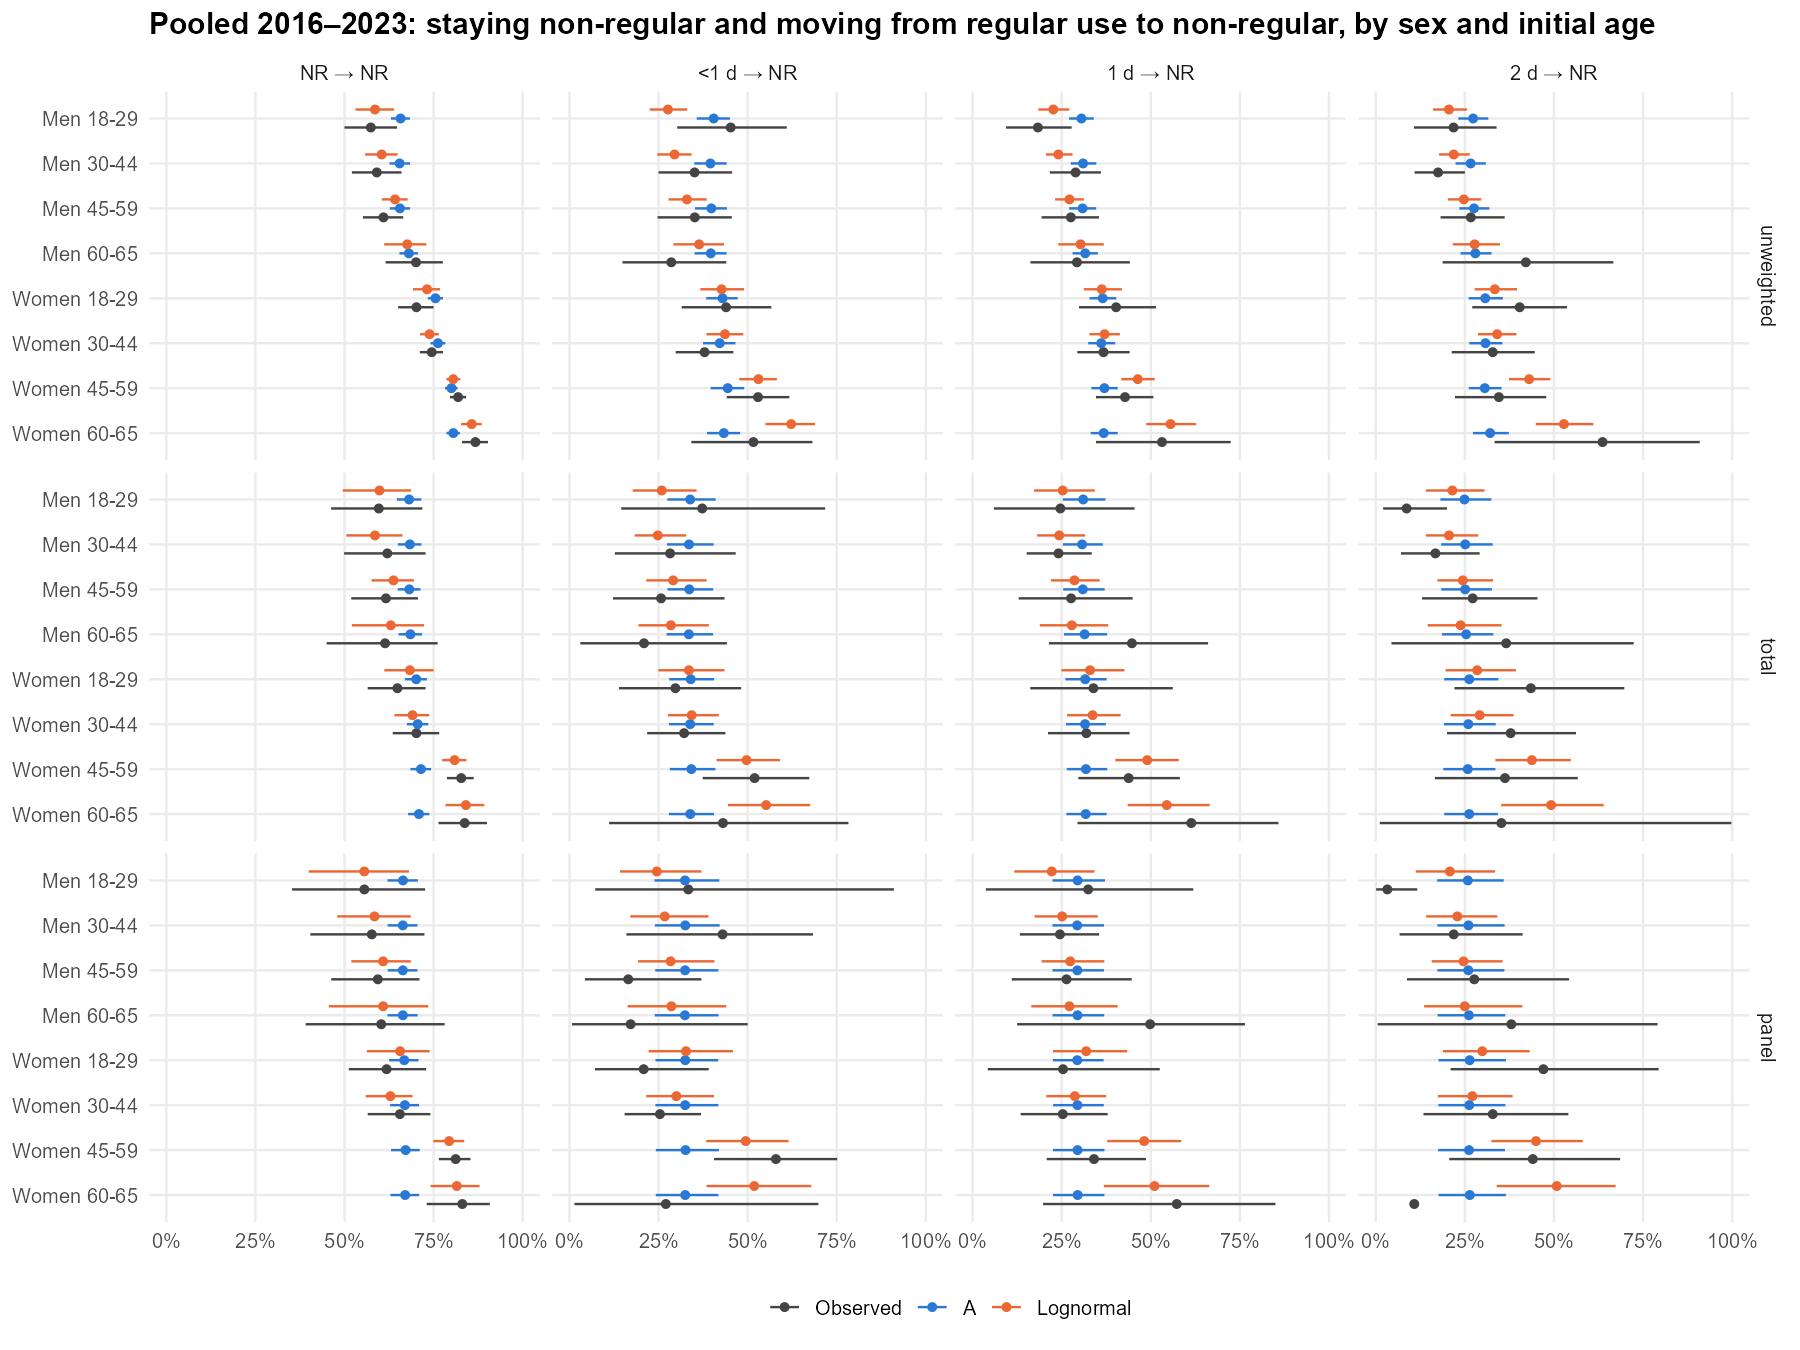

Elapsed: 0.02 minutes


In [17]:
#| label: elsoc-s-pooled
.t0 <- Sys.time()
IRdisplay::display_html(paste0(st_css, "<p class=\"stm-lv\">", lv_label["pooled"], "</p>", paste(vapply(c("All", SA), function(g) block("pooled", g), ""), collapse = "")))
key_tr <- paste(c("NR", "NR", "NR", "F1", "F2", "F3", "F1", "F2"), c("NR", "F1", "F2", "NR", "NR", "NR", "F1", "F2"))
ci3 <- function(lo, hi) ifelse(is.na(lo), "—", sprintf("[%s; %s]", pc1(lo), pc1(hi)))
for (s in SCH) { z <- SM[SM$estimator == "Observed" & SM$level == "pooled" & SM$scheme == s & paste(SM$from, SM$to) %in% key_tr, ]
  z <- z[order(match(z$group, c("All", SA)), match(paste(z$from, z$to), key_tr)), ]
  show_table(data.frame(Group = group_label(z$group), Transition = paste(st_short[z$from], "→", st_short[z$to]), `n origin` = z$n_origin, `Persons in stratum` = z$n_persons_stratum, `Estimate %` = pc1(z$estimate),
    `Segment bootstrap` = ci3(z$lower, z$upper), `Taylor, strata + segments` = ci3(z$lower_taylor_design, z$upper_taylor_design), `Taylor, clustered by person` = ci3(z$lower_taylor_person, z$upper_taylor_person), check.names = FALSE),
    paste0("Pooled 2016–2023, ", sch_label[s], ": survey-weighted transition probabilities with three 95% intervals that keep all pairs of a person together")) }
ob <- SM[SM$estimator == "Observed" & SM$level == "pooled" & is.finite(SM$se_taylor_design) & SM$se_taylor_design > 0, ]
cmp <- do.call(rbind, lapply(split(ob, ob$scheme), function(z) data.frame(scheme = z$scheme[1], cells = nrow(z), `median SE person / independent pairs` = stats::median(z$se_taylor_person / z$se_taylor_independent, na.rm = TRUE),
  `NR → NR, all pairs: person / independent` = z$se_taylor_person[z$group == "All" & z$from == "NR" & z$to == "NR"] / z$se_taylor_independent[z$group == "All" & z$from == "NR" & z$to == "NR"],
  `median SE person / design` = stats::median(z$se_taylor_person / z$se_taylor_design, na.rm = TRUE), `median SE bootstrap / design` = stats::median(z$se_boot / z$se_taylor_design, na.rm = TRUE),
  `90th percentile bootstrap / design` = stats::quantile(z$se_boot / z$se_taylor_design, .9, na.rm = TRUE, names = FALSE), check.names = FALSE)))
show_table(cmp[match(SCH, cmp$scheme), ], "Pooled cells: ratios of standard errors. Independent pairs = Taylor ignoring that a person contributes several pairs; person = clustered by idencuesta; design = strata + segments", digits = 3)
fz <- SM[SM$level == "pooled" & SM$group != "All" & paste(SM$from, SM$to) %in% c("NR NR", "F1 NR", "F2 NR", "F3 NR"), ]
fz$transition <- factor(paste(st_short[fz$from], "→ NR"), paste(st_short[c("NR", "F1", "F2", "F3")], "→ NR"))
p <- ggplot2::ggplot(fz, ggplot2::aes(estimate, factor(group_label(group), rev(group_label(SA))), colour = factor(estimator, EST))) +
  ggplot2::geom_pointrange(ggplot2::aes(xmin = lower, xmax = upper), position = ggplot2::position_dodge(width = .6), size = .2, na.rm = TRUE) + ggplot2::facet_grid(factor(scheme, SCH) ~ transition) +
  ggplot2::scale_x_continuous(labels = scales::percent) + ggplot2::scale_colour_manual(values = c(Observed = "#444444", A = "#2a78d6", Lognormal = "#eb6834")) +
  ggplot2::labs(x = NULL, y = NULL, colour = NULL, title = "Pooled 2016–2023: staying non-regular and moving from regular use to non-regular, by sex and initial age") + plot_theme()
show_plot_s(p, "pooled_key_transitions", 12, 9)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Validation

The first checks table lists what the weighting scenarios verified on the real data in this run: unique identifiers, the MD5 of the file, the identity between the panel weight and `tipo_atricion`, positive weights on every domain, the exact reproduction of the published unweighted tables and flow counts under the published rule, weighted rows that sum to one and events that sum to their origin, deltas paired on aligned replicates, the availability of the Taylor check, the accounting of the kept missing-date pairs, and the hash of the published tables. The second lists the checks of the state-transition part: pair counts equal to the weighting flow, positive weights, the replicate path reproducing the direct estimates, Taylor point estimates equal to the observed ones, NR→NR and frequency-block counts equal to the published S09 and S10 tables, rows that sum to one, a main lognormal fit that predicts every cell and origin, a tuned k for matrix A that is interior or on a flat stretch at the edge of the grid, lognormal fits in at least 99% of the replicates, complete model estimates for every observed origin, and unchanged earlier tables. Each check is marked as a data check, an identity between two computations, or a declaration; the one declaration records that no pooled interval assumes independent pairs.


In [18]:
#| label: elsoc-w-validation
.t0 <- Sys.time()
val <- wt("validation"); stopifnot(all(val$passed)); show_table(val, "Weighting scenarios: checks executed on the real data in this run")
sv <- stt("validation"); stopifnot(all(sv$passed)); show_table(sv, "State transitions: checks run in this execution (kind: data check, identity of two computations, or declaration)")
cat(length(list.files(s_dir, pattern = "^states_.*\\.csv$")), "states_*.csv tables in", basename(s_dir), "\n")
up <- wt("unique_persons"); cs <- changes[changes$group == "All" & changes$item == "s09" & changes$event == "same" & changes$estimator == "unweighted_general", ]
stopifnot(up$n_pairs_total[up$item == "s09"] == sum(cs$n_origin))
files <- list.files(w_dir, pattern = "^weights_.*\\.csv$"); cat(length(files), "weights_*.csv tables in", basename(w_dir), "\n")
cat("Published unweighted tables unchanged (hash check); no pooled independent-person inference; no microdata exported.\n")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


check,kind,passed
unique_longitudinal_ids,data_check,TRUE
md5_matches_published_provenance,data_check,TRUE
panel_weight_equals_tipo_atricion_2016-2018,data_check,TRUE
total_weight_positive_for_all_pairs_2016-2018,data_check,TRUE
panel_weight_equals_tipo_atricion_2018-2021,data_check,TRUE
total_weight_positive_for_all_pairs_2018-2021,data_check,TRUE
panel_weight_equals_tipo_atricion_2021-2023,data_check,TRUE
total_weight_positive_for_all_pairs_2021-2023,data_check,TRUE
flow_counts_and_published_unweighted_tables_reproduced,data_check,TRUE
weighted_rows_sum_to_one_and_events_to_origin,data_check,TRUE


check,kind,passed
md5_matches_published_provenance,data_check,TRUE
unique_longitudinal_ids,data_check,TRUE
pair_counts_match_weighting_notebook_flow,data_check,TRUE
total_weight_positive_for_all_state_pairs,data_check,TRUE
panel_weight_positive_for_panel_state_pairs,data_check,TRUE
replicate_path_reproduces_direct_estimates,identity,TRUE
taylor_point_equals_observed,identity,TRUE
frequency_block_counts_equal_published_S10_matrices,data_check,TRUE
NR_to_NR_counts_equal_published_S09_matrices,data_check,TRUE
every_estimated_row_sums_to_one,data_check,TRUE


13 states_*.csv tables in intervals 


23 weights_*.csv tables in intervals 


Published unweighted tables unchanged (hash check); no pooled independent-person inference; no microdata exported.


Elapsed: 0.00 minutes


## Sources, decisions and reproducibility

- Data: COES, *Estudio Longitudinal Social de Chile 2016-2023*, Harvard Dataverse [doi:10.7910/DVN/LD4BPH](https://doi.org/10.7910/DVN/LD4BPH), version 3.0 (2024-12-27), file `ELSOC_Wide_2016_2023.sav`, CC0 1.0; read from the encrypted repository copy `_elsoc/elsoc_wide_2016_2023.tar.xz.enc`.
- Weights: *Ponderadores longitudinales ELSOC. Documento de referencia* (Equipo ELSOC, March 2023, [pondedradores-long-elsoc.netlify.app](https://pondedradores-long-elsoc.netlify.app/)); code [elsoc-coes/ponderadores-long](https://github.com/elsoc-coes/ponderadores-long), commit `475c7e32becc1451e8d40fb9b8ef0b79d4e5885f`; methodological manual [elsoc-coes/manual-elsoc](https://github.com/elsoc-coes/manual-elsoc/), commit `edd00962c2e7df86ccf90f28bf9fc7fade186b37`; variable listing 2023 and CAPI questionnaires 2023 in `_elsoc/docs/`.
- Items: questionnaires 2016 (p. 23), 2018 (pp. 22–23), 2021 call A (pp. 7 and 10) and 2023 CAPI sheets, all listed in [INTERVALS.md](__andres_control/elsoc_2021_2023_exploration/INTERVALS.md) and [WEIGHTING_PLAN.md](__andres_control/elsoc_2021_2023_exploration/WEIGHTING_PLAN.md); the CATI 2023 instrument and the individual interview mode remain pending.
- Decisions by the user (2026-10-21): all three intervals weighted, 2023 weights used under the stated assumption; unweighted estimates as the reference; missing destination dates do not exclude a pair; panel scenario kept and labelled; destination-wave weight; M1 and M2 shown separately and pooled with the weights as delivered; no additional trimming in the main estimates, p99 cap as sensitivity; no extra attrition adjustment; original S10 categories; intervals reviewed separately before any pooling. Later the same day: transition matrices with non-regular use as a state, by sex, age group and origin wave, with matrix A and the lognormal as in EPS under the three weights, and survey-weighted estimates pooled over the intervals with subject-clustered intervals.
- State transitions: [state_transitions.R](__andres_control/elsoc_2021_2023_exploration/state_transitions.R) writes `intervals/states_*.csv`; it follows `ep_Afit`, `ep_tune`, `ep_fit` and `ep_matrices` of `__andres_control/eps_markov_core.R`, with the k grid extended and the lognormal amount observed in day bands. The interval-censored lognormal is fitted with `survival::survreg`.
- Reproduction: from the repository root, `Rscript __andres_control/elsoc_2021_2023_exploration/weight_scenarios.R` (set `ELSOC_WEIGHTS_OUTPUT` to a project-relative folder for an independent copy), then `Rscript __andres_control/elsoc_2021_2023_exploration/state_transitions.R` (`ELSOC_STATES_OUTPUT` for an independent copy, `ELSOC_STATES_B` to change the number of replicates), then this notebook with the project's R kernel; the HTML is rendered to the repository root by the Quarto project in `__andres_control/`. The notebook is built by `_tools/build_elsoc_weighting_notebook.py` from `elsoc_weighting_scenarios_EN.md` and `elsoc_weighting_sections.R`. `ACC_DATA_KEY` is required locally and is never written anywhere.
- If these estimates are later used to tune the microsimulation, they stop being an independent evaluation of it; the comparison with EPS remains an exploratory triangulation, since ELSOC regularity is not EPS consumption and S10 is not grams per day.
